# chip_05_flux_tlqubits — seven Xmons (two flux-tunable SQUIDs) and eight λ/4 resonators on one feedline, on the Quantcore PDK

## 1 · What the chip is

**Source:** `components/python/chip_05_flux_TLQubits.py` (`create_test_chip()`, WRIDHDHI, May 2024; writes
`chip_05_flux_TLQubits_1.0.gds`), Quantcore internal. Spec: `docs/designs/legacy/chip_05_flux_tlqubits.md`.

A 7.5 × 7.5 mm die: one 10/6 µm CPW feedline between two rounded 600 × 200 µm connector pads; eight λ/4
`Coupled Resonator`s (10/10 µm CPW, 200–400 µm couplers, 4250–6200 µm for 5–7.2 GHz) alternating below and above
the feedline; seven `Xmon Cross` qubits whose claws take the resonator tails (galvanically: `ground=False`, no end
cap); Q4 and Q5 are SQUIDs with 4/6 µm flux lines from two small pads at the top and bottom edge; R8 is a bare
resonator with its own open end; eight 3 × 15 arrays of 30 µm flux-trap holes; two HSQ junction test pads; HSQ
corner markers.

| | the rebuild keeps (source-faithful) | the Quantcore PDK changes |
|---|---|---|
| resonators, Xmons | the eight `Coupled Resonator`s and seven `Xmon Cross`es with the legacy parameters, positions and rotations; each tail runs into its claw tail (the source's own galvanic join, `W_Qi` wires); R8 with its own open end | — |
| feedline, pads | rounded 600 × 200 µm "Connector Pad" geometry (`ConnectorPad`, fab drawing), 10/6 µm CPW (`CpwSegment`) | pads with their outer etch **`pad_edge` = 100 µm** from the die edge (legacy: at the edge): feedline 5160 µm (legacy 5360 µm between the pad tips) |
| flux lines | 4/6 µm CPW routes from the two small "Connector Pad"s into the Xmon flux ports, legacy x waypoints, shorted beside the SQUID | the flux pads also sit 100 µm from the edge; each line's jog keeps its legacy distance from its pad port (155 / 360 µm), so the corner radii 75 / 100 µm (#11) still fit; the last straight into the SQUID is 100 µm shorter |
| junctions | the author's HSQ trilayer cells (`Trilayer Junction HSQ`, `Trilayer Squid HSQ`) at the legacy fingers (js · 0.1 × 0.6 µm; indexing fixed, #11) under the legacy CLEARER windows | valued on the PDK process: Q1–Q3 45 kΩ (in the window); Q6 (js 8) 28.1 kΩ and the SQUIDs Q4/Q5 22.5 kΩ (parallel) are outside 40–50 kΩ → **flagged** (`pdk_rn`), not retuned |
| cheese | the source's own eight 3 × 15 arrays of 30 µm holes (`FluxHoleArray`) | none added: **the original's cheese wins** (`cheese: "original"`) |
| placement | everything relative to the feedline | the circuit **centred in the die** where it is more than 50 µm off (step 7) |
| frame | the HSQ corner markers (`CornerMarker`, `hsq=True`) | the PDK die frame and device ID `CHIP05` instead of the legacy base-metal corner markers; the labels "500nm", "800nm", "QCG_Nb05_W" are not drawn |

**Approximations** (unchanged from the earlier pass): the flux
lines are Designer routes into the Xmon's flux port (tip 5 µm off the axis, 7.5 µm into the ground, as drawn); the
legacy 1 µm-wide last 50 µm and its ground boxes are not drawn. The junction windows (CLEARER, 30 × 27 µm, 3 µm
towards the cross) are `junction_window=[30, 27, -3]`: metal on `base_metal_addition`, removed from the 1/0 etch at
export, so the trilayer bridges arm and ground there (the FEM export drops the window: in simulation the junction
is the lumped port). The source inserts each junction unrotated with a mirror flag that toggles per qubit (Q2, Q4,
Q6 mirrored about x); on those 180° Xmons `mirror_squid` gives the same orientation.

**Reproduced exactly** (XOR against the author's own PCells and scripts, read-only through `tests/legacy_ref`, step
15): the resonators, the Xmon crosses and claws with their junction windows, the flux holes, the test pads and the
pads + feedline at their PDK position; the six junctions on the junction layers (2/0, 4/0, HSQ) against the legacy
`junction_creator_HSQ` / `squid_creator_HSQ` cells.

### Changes after design review (2026-11-03)

- **#11 junction indexing — fixed.** The source inserts `bot[i-1]` for qubit `i` (0-based), so Q1 got `bot[-1]` =
  the 0.8 µm junction meant for Q6 and Q6 got 0.5 µm. The user: fix it. Now **Q1–Q5 use js 5 (0.5 µm) and Q6
  (the 600 µm cross) js 8 (0.8 µm)**, i.e. `bot[i]`; the junction-layer reference in step 15 calls the legacy
  scripts with the same fixed sizes.
- **#11 flux-line corners — fitted so they cannot break or overlap.** The legacy lines round every corner at 100 µm,
  but FLUX4's jog between the pad (x = 0) and Q4's flux port (x = −175) is only 175 µm: two 100 µm bends need 200 µm,
  so the legacy polygon corners collide. FLUX4 uses r = 75 µm, the largest radius the router fits between the pad
  lead and the jog (80 µm already fails: "straight segment cannot fit"), FLUX5 (300 µm jog, 360 µm lead) keeps the
  legacy r = 100 µm; same waypoints and 4/6 µm CPW, shorted beside the SQUID as before.
- **R8 — the PCell's own open end** (the rule for #13/#26: the later PCell has a dedicated open and short end,
  as in chip_10a, the later version of this chip, which sets R8 `ground=True` and drops the box). R8 (no qubit) ends
  with its own gap cap (`ground=True`); the legacy `resonatorGnd` box (`CUT8`) and the `W_R8` wire are gone.
- **#16 device ID:** `CHIP05` kept; the frame's rule places it (bottom centre if free, else beside the feedline pads
  with a 50 µm gap, else slid along the left/right edge; omitted if nowhere free).
- **#1 / PDK rebuild — junctions.** The author's own HSQ trilayer cells stay (`Trilayer Junction HSQ` / `Trilayer
  Squid HSQ`: fingers on 2/0 + 4/0, spacer 50/0 with the 51–53/0 gradient) at the legacy fingers, valued on the
  **PDK junction rule** (Nb, Δ = 1.4 meV, I_c·R_n = πΔ/2e = 2.20 mV; PDK process R_n·A 13.5 kΩ·µm², assumed by
  the PDK, = 45 kΩ at 0.5 × 0.6 µm — exactly this chip's js 5 junction): Q1–Q3 → 45 kΩ (L_J 6.73 nH), Q6's
  0.8 × 0.6 µm → 28 kΩ, the SQUIDs Q4/Q5 (two js 5 junctions) 22.5 kΩ in parallel at zero flux (the top of their
  flux-tuning range). The earlier assumed J_c = 1 µA/µm² is gone. Values in step 10.
- **Claw-tail gap (#22):** the Xmon's claw tail is cleared by its own `claw_tail_gap` (default: the
  chip CPW gap, 6 µm); `L.xmon` sets it to the legacy `cap_spacing` = 10 µm, as the legacy `Xmon Cross` draws it,
  matching the 10/10 µm resonators.

### PDK conformance pass (notebooks-legacy, 2026-11-18)

- **Pads:** the left feedline pad is placed with `edge="auto"` (outer etch `get_pdk().frame.pad_edge` = 100 µm
  from the die edge), the feedline snaps onto its port with the length the rule leaves on this symmetric chip,
  and the right pad snaps onto the far end (the earlier form had the feedline at (0, 0) and both pads snapped to
  it). The flux pads `PFT` / `PFB` get `edge="auto"` too. DRC `pad_edge` warnings: 4 → 0.
- **Flux lines:** each route follows its moved pad: the jog keeps its legacy distance from the pad port (FLUX4 155
  µm, FLUX5 360 µm), computed from the placed pad, so the legacy corner radii (75 / 100 µm) still fit.
- **Centring:** `L.center_circuit` (each axis only if > 50 µm off).
- **Cheese:** the source etches its own flux holes, so the original wins: `cheese: "original"` (before this pass
  the chip was `"auto"` and the build added the PDK band on top of the holes).
- **Junctions:** the author's HSQ trilayer cells at the legacy fingers (decision #1); `pdk_rn` flags them where
  they leave 40–50 kΩ, never retuned.
- Educative layout: one step per stage (die → pads and feedline → resonators and Xmons → flux lines → holes,
  test pads and centring → DRC → LOM → FEM → iterate → export → snapshots).

## 2 · Setup and the Quantcore PDK

The helpers keep the cells short: `_common` (`C`) holds the netlist / LOM / FEM-export / snapshot helpers and
the PDK checks shared by every design notebook; `_legacy` (`L`) maps the legacy PCell parameters onto the
Quantcore cells, draws the legacy reference with the author's own legacy code (read-only), and holds the step
helpers of these notebooks. `LIVE` decides whether the design is pushed to a running KLayout (`QCC_LIVE=0`
for batch runs: nothing reaches KLayout).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                       # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
sys.path.insert(0, str(ROOT / "examples" / "designs" / "legacy"))
LIVE = os.environ.get("QCC_LIVE", "1") == "1"       # live KLayout by default; QCC_LIVE=0 for batch runs
import _common as C                                  # netlist / LOM / FEM-export / snapshot / PDK-check helpers
import _legacy as L                                  # legacy frame shift, parameter mapping, legacy reference, steps
from quantcore_circuits.assembly.drc import device_id_block
from quantcore_circuits.layouts.others.test_pads import legacy_test_pad_params
from IPython.display import Image, Markdown, display
from quantcore_circuits.designer import Designer
from quantcore_circuits.pdk import get_pdk

ID, OUT = "chip_05_flux_tlqubits", Path("examples/designs/legacy")

The PDK facts this rebuild uses, read from `get_pdk()` (nothing below is typed in by hand). The rules that
change a legacy chip are the **pad rule** (step 4), the **junction rule** (step 5), the **3/0 keep-out**
and the **cheese rule** (drawn by the build, step 14) and the centring of the content (step 7).

In [3]:
CHEESE_NOTE = 'original — the source etches eight 3 × 15 arrays of 30 µm flux holes (FluxHoleArray); no PDK band'
display(Markdown(L.pdk_facts_md(CHEESE_NOTE)))

| PDK item | value |
|---|---|
| PDK | `quantcore_nb_sapphire_v1` (version 3) |
| stack | sapphire, 650 µm, ε_r 10.25; Nb film (sheet metal in the FEM exports, 0.2 µm for the analytic CPW formulas) |
| CPW default | 10 µm centre, 6 µm gap, bends r = 100 µm |
| die frame | L-shaped dicing markers 25 µm wide (250 µm legs, 1000/0), 3 × 3 alignment grids (1001/0) in 500 µm corner squares, design area 100 µm inside the die edge, device ID optional (bottom centre, or beside the pads) |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (the design-area margin) from the die edge, whatever the original did (`edge="auto"`, DRC design warning `pad_edge`) |
| junction rule | Nb/AlOx/Nb trilayer, Δ = 1.4 meV (I_c·R_n = πΔ/2e), R_n 40–50 kΩ (nominal 45), qubits 4–8 GHz; R_n·A 13500 Ω·µm² and C_J 50 fF/µm² assumed; cells `Quantcore Junction` / `Quantcore Squid` (DRC design warnings `pdk_rn`, `pdk_fq`: flagged, never retuned) |
| 3/0 keep-out | second-metal etch: routes + 10 µm, components' etch bbox + 24 µm, other 1/0 shapes + 9 µm (filled) |
| cheese rule | 3 rows of 5 µm squares, 20 µm gaps, in a band around the 3/0 keep-outs; **the original design's own cheese wins** (chip `cheese`: `"auto"` / `"pdk"` / `"original"`). This chip: original — the source etches eight 3 × 15 arrays of 30 µm flux holes (FluxHoleArray); no PDK band |

### The source's numbers

`chip_05_flux_TLQubits.py`'s numbers in its own (0, 0)-centred frame (µm); `L.place` shifts them by (+3750, +3750)
into the Designer frame and turns the legacy `Trans` code into degrees; `L.xmon`, `L.coupled_resonator`,
`L.connector_pad`, `L.cpw_segment` map the legacy PCell parameters. Rows: each resonator (coupler x, y, mirror,
overrides of the common parameters, the source's target frequency), each Xmon (legacy centre and junction scale
js; Q4, Q5 SQUIDs; Q6 the 600 µm cross; Q7 no junction), the flux-hole arrays, the HSQ test pads and the two flux
lines (pad, legacy jog distance from the pad port, jog x, corner radius).

In [4]:
# chip_05_flux_TLQubits.py, legacy frame (µm)
FEED = dict(length=7500 - 2000 - 40, gap=6, lc_thickness=2, rc_thickness=2)               # "Coplanar Waveguide"
PAD = dict(trace_width=10, trace_gap=6, pad_height=200, pad_width=600, conn_height=500, round=True, sim=False)
TINY = dict(trace_width=4, pad_height=150, pad_width=400, conn_height=100, round=True, sim=False)   # flux pads
X_PAD, Y_TINY = 3750 - 1000 - 70, 3750 - 500 - 70 - 25    # legacy pad ports: feedline ends ±2680, flux pads ±3155
RES = dict(cpw_len=4660, gap=10, clength=200, cgap=7, width=300, flip=False, neck_length=400, ground=False)
XMON = dict(width=400, handle=1, cap_spacing=10, da=3, thickness=50, pthickness=30, fwidth=30, spacing=20, ggap=15)
BIG = XMON | dict(width=600)
#         n  x_res  y_res mirror  overrides                                       f (GHz)
RROWS = [(1, -2000, -38, False, dict(cpw_len=4740),                              6.5),
         (2, -1430,  33, True,  dict(cpw_len=4920, flip=True),                   6.25),
         (3,  -850, -33, False, dict(cpw_len=5590, flip=True, clength=400),      5.5),
         (4,  -280,  33, True,  dict(cpw_len=6200, width=400),                   5.0),
         (5,   280, -38, False, dict(cpw_len=5200, clength=250),                 6.0),
         (6,   850,  33, True,  dict(cpw_len=4250),                              7.2),
         (7,  1430, -38, False, dict(cpw_len=5840, flip=True, clength=400),      5.25),
         (8,  2000,  33, True,  dict(cpw_len=4500, flip=True, clength=400, ground=True), 7.0)]  # R8: no qubit,
#                                                    its own open end (gap cap) instead of the legacy CUT8 box
#          x      y    junction (js · 0.1 µm: bot[i]; the legacy bot[i-1] bug fixed, #11)   Q4, Q5: SQUIDs
QUBITS = [(-1950, -2218, 5), (-1480, 2391, 5), (-800, -2237, 5), (-180, 2492, 5), (305, -2219, 5), (900, 2203, 8),
          (1480, -2503, None)]                                    # Q6 has the 600 µm cross; Q7 has no junction
SQUIDS, SECOND_FINGER = (4, 5), 0.6
WINDOW, USE_WINDOWS = [30, 27, -3], True    # legacy CLEARER 30 × 27 µm, 3 µm towards the cross (FEM export drops it)
MIRROR = (2, 4, 6)   # the source's junction mirror flag toggles per qubit: on these 180° Xmons = mirror_squid
HOLES = [(-2050, 300), (-1430, -1800), (-850, 300), (-280, -1800), (360, 300), (850, -1800), (1430, 300), (2000, -1800)]
TESTPADS = [(-2850, 2000, 0.5), (2850, -2000, 0.8)]               # testPad_Nb_TL_HSQ.create_testPad(bf / 0.2, 0.6)
#        flux pad, jog distance from its port (legacy), jog x (legacy), corner radius (#11)
FLUX = {4: ("PFT", 155, -175, 75),     # legacy: port y 3155, jog y 3000; 175 µm jog < 2 × 100 → r 75
        5: ("PFB", 360, 300, 100)}     # legacy: port y −3155, jog y −2795; the legacy r 100

## 3 · The die and the frame

`Designer(ID, box=...)` starts an empty 7.5 × 7.5 mm die (the PDK standard die). The PDK frame is drawn on every
build: four L-shaped dicing markers (1000/0), the 3 × 3 alignment grids (1001/0), the chip boundary (100/0) and the
device ID `CHIP05` (`name_chip`). `cheese="original"`: this design brings its own cheese (the flux holes, step 7),
so the build adds no PDK band.

(0.0, 0.0, 7500.0, 7500.0) quantcore_nb_sapphire_v1


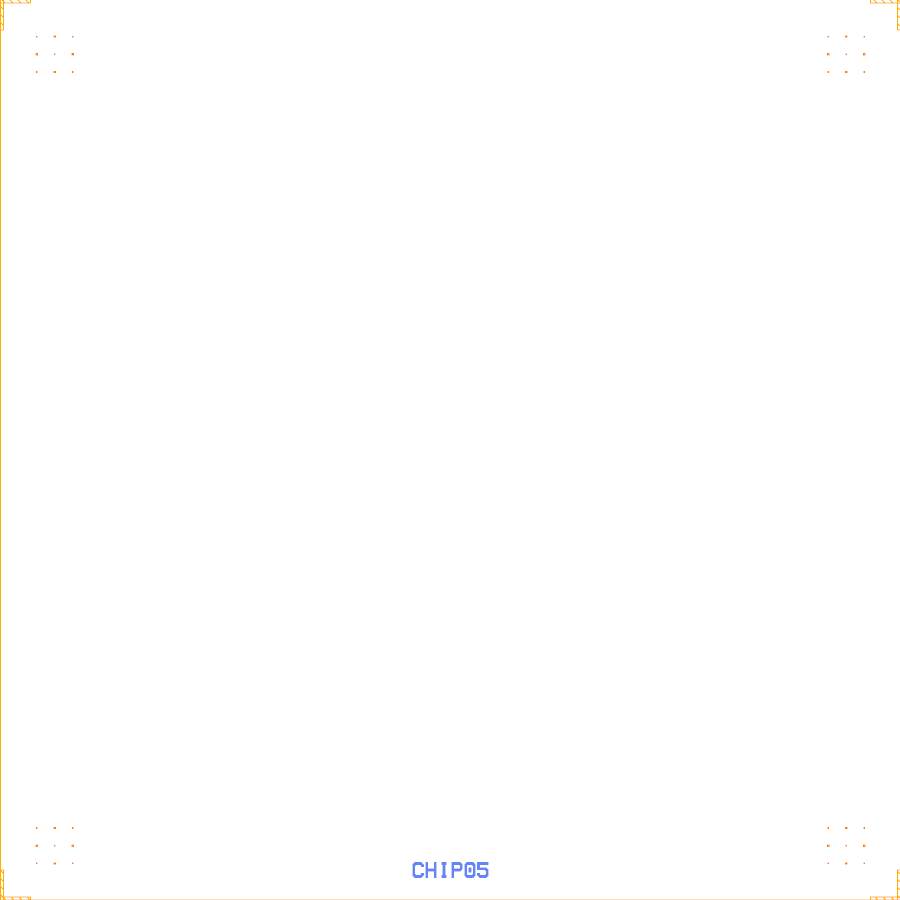

WindowsPath('build/legacy_steps/chip_05_flux_tlqubits_1_frame.png')

In [5]:
d = Designer(ID, box=(0, 0, L.W, L.H), chip={"name_chip": "CHIP05", "cheese": "original"}, live=LIVE)
print(d.design.chip.box, d.design.pdk)
L.step_snapshot(d, "1_frame")

## 4 · Pads (PDK pad rule) and the feedline

The rounded legacy "Connector Pad" (`ConnectorPad`: 600 × 200 µm pad, 500 µm taper) goes at the left end of the
feedline with the legacy rotation (rot 3); `edge="auto"` slides it perpendicular to its nearest die edge until the
outer edge of its etch is **`pad_edge` = 100 µm** from the die edge (`get_pdk().frame.pad_edge`, the design-area
margin): the PDK pad rule, which wins over the original (whose pads reached the die edge).

The feedline (`CpwSegment`, 10/6 µm) snaps onto the left pad's port with the length the rule leaves on this
symmetric chip (die width − 2 × the port's x), and the right pad snaps onto its far end: pad, feedline and pad are
one conductor in the netlist. The two small flux pads (`ConnectorPad`, 400 × 150 µm, 4 µm trace; legacy "cpadB" at
the top, "cpadT" mirrored at the bottom) keep their legacy x and get `edge="auto"` as well: their ports move 100
µm towards the centre. `L.edge_gaps` measures the four pads from the built etch; `device_id_block` says where the
frame put the device ID (the edge centres hold pads, so it slides to a free spot).

pad etch → die edge (µm): {'PL': 100.0, 'PR': 100.0, 'PFT': 100.0, 'PFB': 100.0} | rule: 100.0
feedline 5160 µm (legacy 5360 µm between the pad tips) | flux-pad ports, legacy frame y: [3055.0, -3055.0] (legacy ±3155)


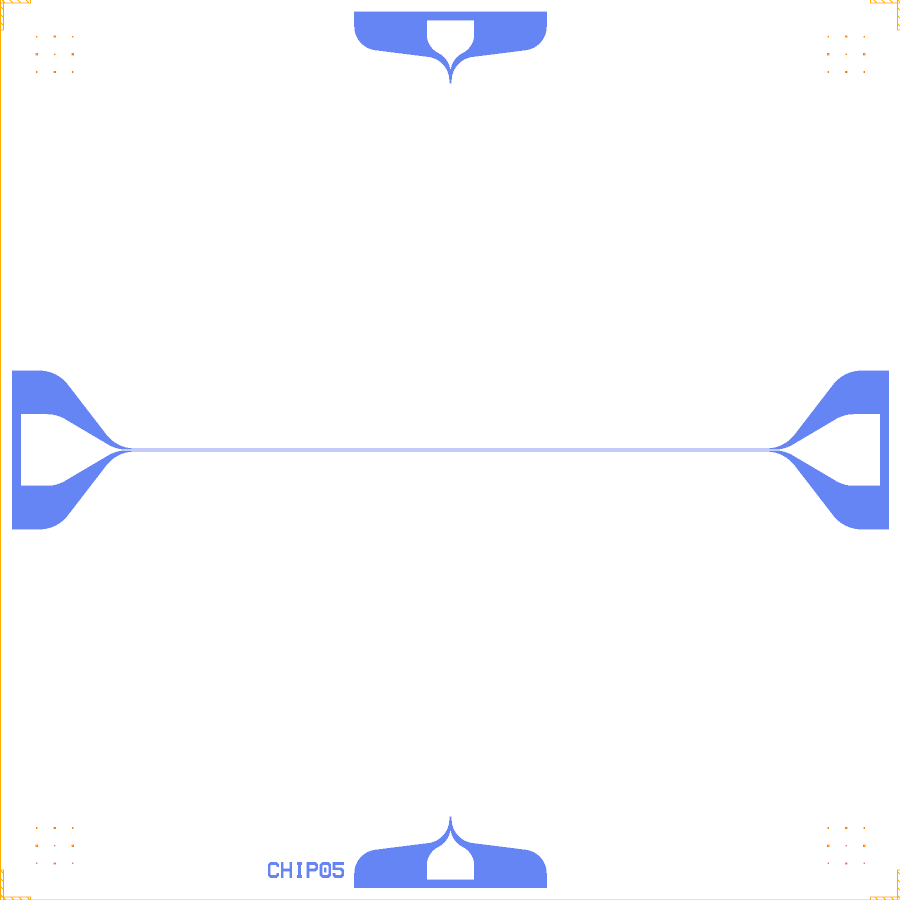

device ID block (µm): (2195,100;2895,400)


In [6]:
d.add("PL", "ConnectorPad", **L.place(-2500, 0, 3), edge="auto", **L.connector_pad(**PAD))   # legacy port (−2680, 0), rot 3
x_pad = L.W / 2 - C.port_xy(d, "PL.a")[0]          # feedline half-length the rule leaves (legacy frame)
with d.batch():
    d.add("FL", "CpwSegment", snap="a", to="PL.a", **L.cpw_segment(**FEED | {"length": round(2 * x_pad, 3)}))
    d.add("PR", "ConnectorPad", snap="a", to="FL.b", **L.connector_pad(**PAD))           # legacy (+2680, 0), rot 1
    d.add("PFT", "ConnectorPad", **L.place(0, Y_TINY, 2, False), edge="auto", **L.connector_pad(**TINY))  # "cpadB"
    d.add("PFB", "ConnectorPad", **L.place(0, -Y_TINY, 2, True), edge="auto", **L.connector_pad(**TINY))  # "cpadT"
print("pad etch → die edge (µm):", L.edge_gaps(d), "| rule:", get_pdk().frame.pad_edge)
print(f"feedline {2 * x_pad:.0f} µm (legacy {2 * X_PAD} µm between the pad tips) | flux-pad ports, legacy frame y:",
      [round(C.port_xy(d, p)[1] - L.H / 2, 1) for p in ("PFT.a", "PFB.a")], f"(legacy ±{Y_TINY})")
L.step_snapshot(d, "2_pads")
print("device ID block (µm):", device_id_block(d.result))

## 5 · Components: resonators, Xmons and their junctions

Each `CoupledResonator` is the legacy `Coupled Resonator` PCell: a meandered 10/10 µm λ/4 (`cpw_len`), shorted at
the end of its coupler beside the feedline behind a 7 µm ground strip (12 µm for the three at y = −38). R1–R7 end
**uncapped** (`ground=False`, the PCell's "xmon connector" end) and their tail runs into the Xmon's claw tail, as
the source places them (galvanic): `d.couple("W_Qi", "Qi.claw_n", "Ri.end", wire=True)` declares that join, so the
netlist merges the tail end and the claw. R8 (no qubit) has the PCell's own open end (`ground=True`).
`d.couple("K_Ri", "Ri", "FL")` declares the coupler ∥ feedline coupling (a hanger κ in the netlist); `d.targets`
stores the source's frequencies. Q4 and Q5 get a flux port (`flux_port=True`, the tip 5 µm off the axis and 7.5 µm
into the ground, as the source draws it).

**Junctions.** Each Xmon draws the author's first-generation HSQ trilayer cell (`Trilayer Junction HSQ`, Q4 and Q5
`Trilayer Squid HSQ`: fingers on 2/0 + 4/0, spacer 50/0 with the 51–53/0 gradient) at the **legacy fingers**,
js · 0.1 µm × 0.6 µm (`junction_params`), as the design decision keeps it, under the legacy 30 × 27 µm CLEARER window.
`L.jj` values the drawn fingers on the PDK process (R_n·A 13.5 kΩ·µm²): js 5 (0.30 µm²) → 45 kΩ, exactly the PDK
nominal; Q6's js 8 → 28.1 kΩ and the two-junction SQUIDs 22.5 kΩ (parallel, at zero flux) lie outside 40–50 kΩ,
so DRC flags them (`pdk_rn`, step 8) — flagged, never retuned. Q7 has no junction (`No Squid`).

PDK junction rule: Nb trilayer, Δ = 1.4 meV → I_c·R_n = πΔ/2e = 2.199 mV; PDK process R_n·A = 13500 Ω·µm² (J_c = 0.163 µA/µm²; nominal 0.5 × 0.6 µm → 45 kΩ, L_J 6.73 nH), C_J = 50 fF/µm² (R_n·A and C_J assumed by the PDK).


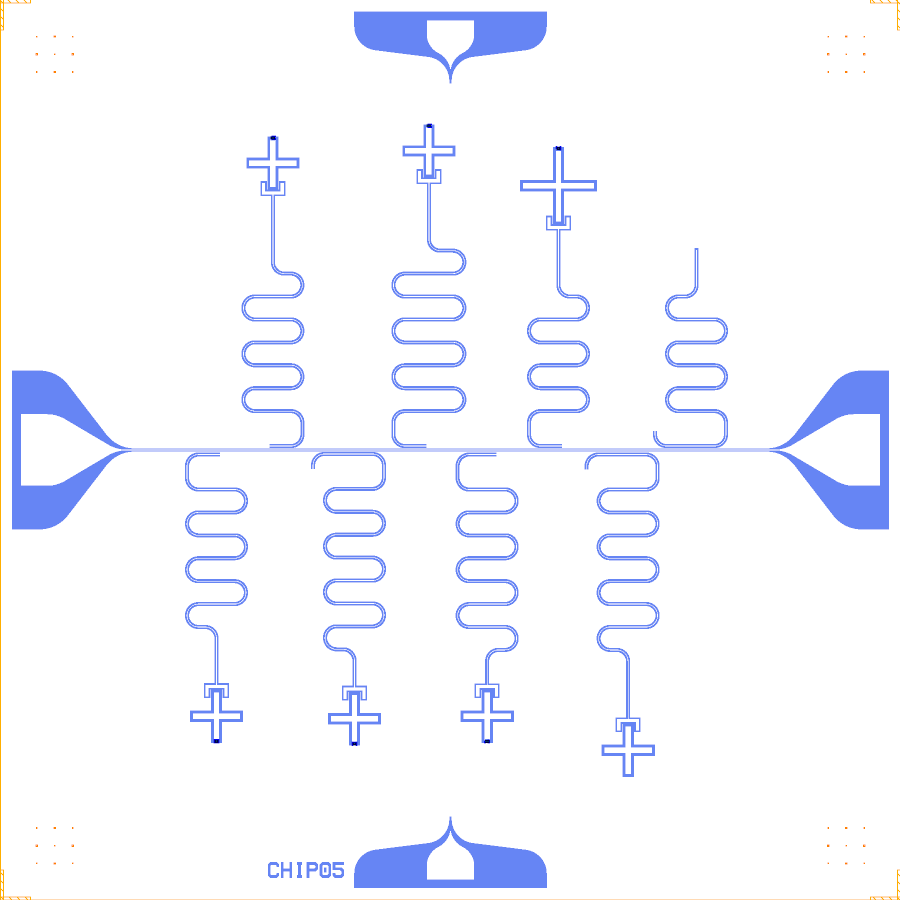

WindowsPath('build/legacy_steps/chip_05_flux_tlqubits_3_components.png')

In [7]:
with d.batch():
    for n, x, y, mirror, over, f in RROWS:
        d.add(f"R{n}", "CoupledResonator", **L.place(x, y, 0, mirror), **L.coupled_resonator(**RES | over))
        d.couple(f"K_R{n}", f"R{n}", "FL", note="coupler parallel to the feedline, 7 µm ground strip (12 µm at y=-38)")
        d.targets(**{f"R{n}": {"f_GHz": f}})
    for i, (x, y, js) in enumerate(QUBITS, 1):
        squid = i in SQUIDS
        flux = dict(flux_port=True, flux_x=-5.0, flux_tip_depth=7.5, flux_slot=[]) if squid else {}
        d.add(f"Q{i}", "Xmon", **L.place(x, y, 0 if i % 2 else 2), **L.xmon(**(BIG if i == 6 else XMON)),
              junction_type=("Trilayer Squid HSQ" if squid else "Trilayer Junction HSQ") if js else "No Squid",
              junction_params={"finger_width": 0.1 * js, "second_finger_width": SECOND_FINGER} if js else {},
              junction_window=WINDOW if js and USE_WINDOWS else [], mirror_squid=i in MIRROR,
              junction=L.jj(0.1 * js, SECOND_FINGER, n=2 if squid else 1) if js else None, **flux)
        d.couple(f"W_Q{i}", f"Q{i}.claw_n", f"R{i}.end", wire=True, note="tail without end cap inside the claw tail")
        if js:
            d.sim_group(f"Q{i}R{i}", [f"Q{i}", f"R{i}"])
print(L.rule_md())
L.step_snapshot(d, "3_components")

## 6 · Routes: the flux lines

The two flux lines are Designer routes (`d.route`, 4/6 µm CPW) from the flux pads' ports into the Xmon flux
ports, through two waypoints: straight down (up) from the pad to a jog, across to the qubit's x, then into the
SQUID's flux port. The pads moved 100 µm in (step 4), so each jog is placed at its **legacy distance from the moved
pad port** (FLUX4 155 µm, FLUX5 360 µm), computed from the placed pad: the first corner keeps the room it had in
the source, and the corner radii of the design decision (FLUX4 75 µm, the largest that fits its 175 µm jog; FLUX5 the
legacy 100 µm) still fit. What shrinks is the last straight into the SQUID (100 µm shorter).

In the netlist a flux line is a control line of its qubit (no circuit element; the pad port is dropped).

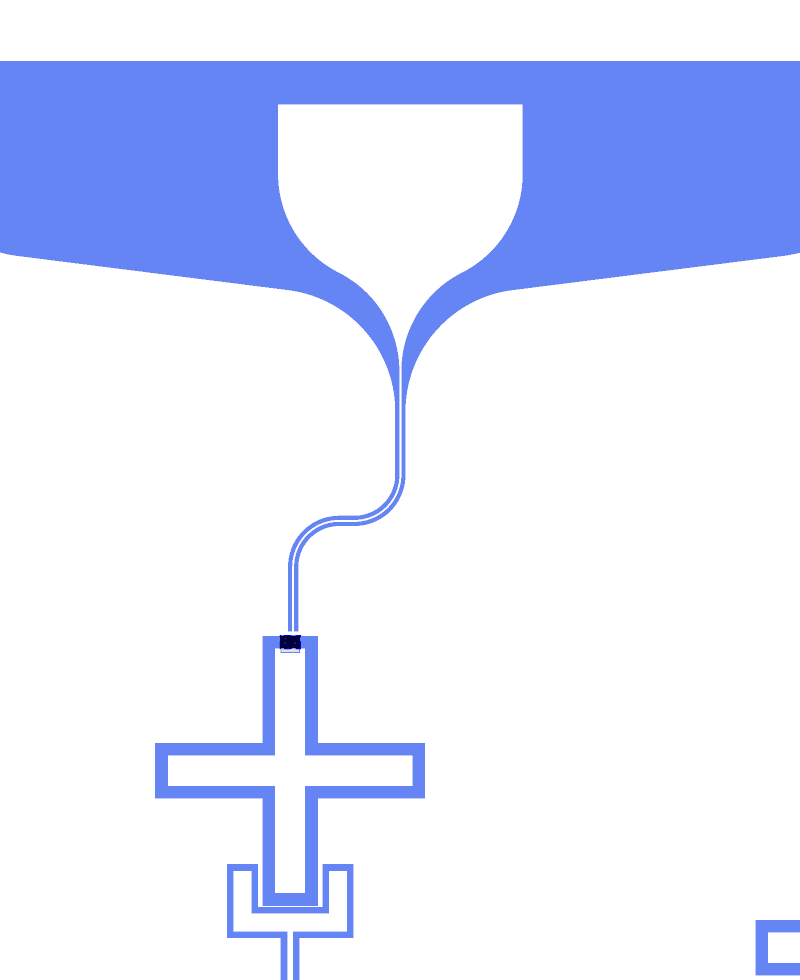

FLUX4: jog y +2900.0 (legacy 3000), 155 µm from PFT.a, r = 75 µm, last straight to Q4.flux 105.5 µm, length 446.1 µm
FLUX5: jog y -2695.0 (legacy −2795), 360 µm from PFB.a, r = 100 µm, last straight to Q5.flux 148.5 µm, length 822.7 µm


In [8]:
JOG = {}
for q, (pad, lead, x_jog, r) in FLUX.items():
    x0, y0 = C.port_xy(d, f"{pad}.a")
    JOG[q] = y0 - lead if y0 > L.H / 2 else y0 + lead          # the jog keeps its legacy distance from the moved pad
with d.batch():
    for q, (pad, lead, x_jog, r) in FLUX.items():
        d.route(f"FLUX{q}", f"{pad}.a", f"Q{q}.flux", nodes=[L.at(0, JOG[q] - L.H / 2), L.at(x_jog, JOG[q] - L.H / 2)],
                a=4, b=6, r=r)
L.step_snapshot(d, "4_flux", box=(3100, 5900, 4400, 7500), size=(800, 980), width=400)
for q, (pad, lead, x_jog, r) in FLUX.items():
    yq = C.port_xy(d, f"Q{q}.flux")[1]
    print(f"FLUX{q}: jog y {JOG[q] - L.H / 2:+.1f} (legacy {'3000' if q == 4 else '−2795'}), {lead} µm from {pad}.a, "
          f"r = {r} µm, last straight to Q{q}.flux {abs(JOG[q] - yq) - r:.1f} µm, length {d.result.route_lengths()[f'FLUX{q}']:.1f} µm")

## 7 · The source's cheese, test pads and markers, and centring

**Cheese — the original wins.** The source etches its own flux-trapping holes: eight arrays of 3 × 15 squares of
30 µm on a 100 µm pitch, between the resonators above and below the feedline (`FluxHoleArray`, drawn on 1/0). The
chip keeps `cheese="original"` (step 3), so the build adds no PDK band. The two HSQ junction test pads
(`JunctionTestPads`, `testPad_Nb_TL_HSQ` with the 0.5 and 0.8 µm fingers) and the four HSQ corner markers
(`CornerMarker`, HSQ layer) keep their legacy places; they have no ports.

**Centring (PDK placement rule).** `L.center_circuit` measures the circuit (instances and routes) and shifts the
design so it sits in the middle of the die, each axis only if it is more than 50 µm off. Then the design is saved:
the JSON is what every later step reads.

centring shift (µm): (0.0, 0.0) | feedline y = 3750.0 | <Designer chip_05_flux_tlqubits: 34 instances, 2 routes, live=False> → examples\designs\legacy\chip_05_flux_tlqubits.json


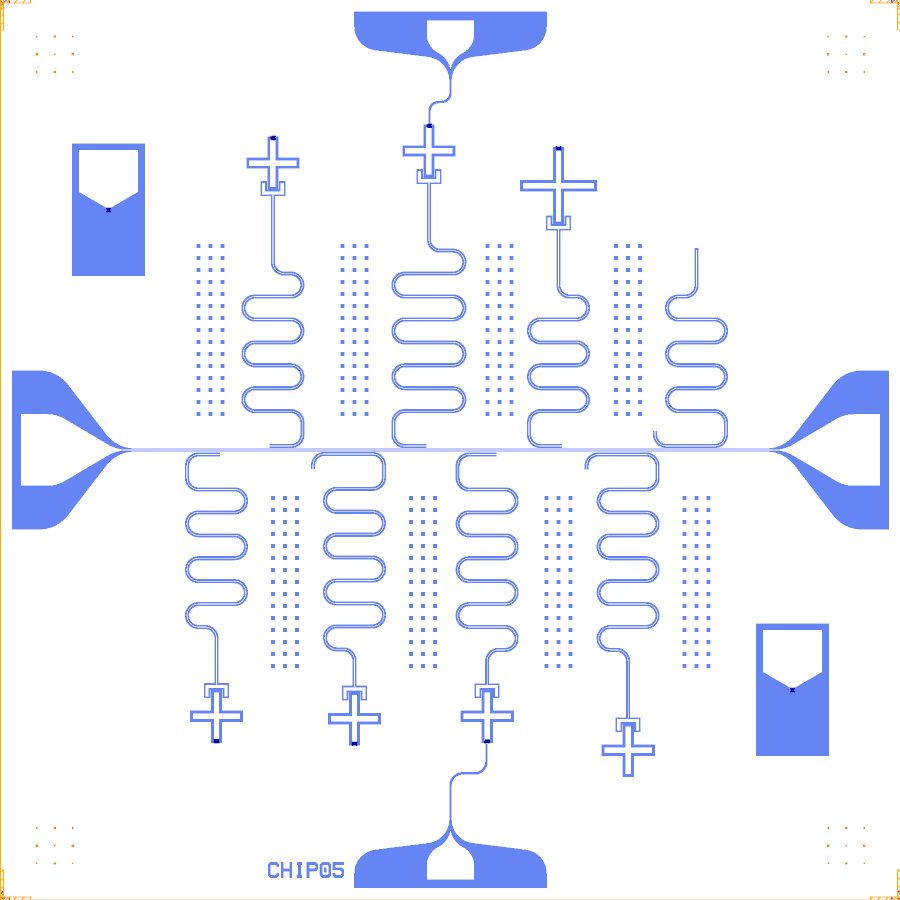

WindowsPath('build/legacy_steps/chip_05_flux_tlqubits_5_centred.png')

In [9]:
with d.batch():
    for k, (x, y) in enumerate(HOLES):
        d.add(f"H{k}", "FluxHoleArray", **L.place(x - 50, y), hole_size=30, pitch_x=100, pitch_y=100, nx=3, ny=15)
    for k, (x, y, bf) in enumerate(TESTPADS, 1):
        d.add(f"TP{k}", "JunctionTestPads", **L.place(x, y), **legacy_test_pad_params("testPad_Nb_TL_HSQ", bf / 0.2, 0.6))
    for k, (x, y, rot) in enumerate([(-3750, -3750, 1), (3750, -3750, 2), (3750, 3750, 3), (-3750, 3750, 0)]):
        d.add(f"HSQ{k}", "CornerMarker", **L.place(x, y, rot), hsq=True, thickness=50, width=150)
SHIFT = L.center_circuit(d)
DESIGN = d.save(OUT / f"{ID}.json")
print("centring shift (µm):", SHIFT, "| feedline y =", round(C.port_xy(d, "FL.a")[1], 1), "|", d, "→", DESIGN)
L.step_snapshot(d, "5_centred")

## 8 · DRC

`d.drc()` builds the chip and checks it: **errors** (overlapping etch of unrelated cells, ports not landing,
parts outside the chip, a route looping over itself or running over a component) must be fixed; **warnings** are
reported for a person to judge (a dangling open end, two cells' bounding boxes touching); **PDK design warnings**
(`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`) flag values outside the PDK margins — they are never retuned for, only
listed. `C.pdk_report(d)` summarises the PDK checks: cheese source, content centring (free text labels left out),
junction types and the design warnings.

Expected (this run): zero errors; `dangling_port` `R8.end` (R8's own open end, nothing joins it by design);
`frame_margin` / `frame_keepout` HSQ0–HSQ3 (the HSQ corner markers reach into the dicing margin and the
dicing-marker areas: legacy positions kept, HSQ layer only, not the base metal); `overlap` Qi / Ri, i = 1 … 7 (each
tail runs into its claw tail: the source's galvanic join, the `W_Qi` wires, so no `dangling_port` there); **3 PDK
design warnings** `pdk_rn`: the SQUIDs Q4 and Q5 (22.5 kΩ in parallel, L_J 3.37 nH) and Q6 (js 8: 28.1 kΩ, L_J
4.21 nH), outside 40–50 kΩ — flagged, not retuned (the design decision keeps the legacy fingers). No `pad_edge` (all
four pads at 100 µm) and no device-ID warning: the frame put `CHIP05` beside the bottom flux pad, on its left,
(2195, 100)–(2895, 400) µm. `pdk_report`: cheese "the original design's own", content centre (+0, +0) µm,
junction types `Trilayer Junction HSQ` × 4, `Trilayer Squid HSQ` × 2, `No Squid` × 1.

In [10]:
drc = d.drc()
print(drc)
display(Markdown(C.pdk_report(d)))

warning dangling_port R8.end is not connected (no route or snap)
warning frame_margin  HSQ0 reaches into the 100 µm die margin (dicing markers)
warning frame_keepout HSQ0 overlaps the dicing_markers_sw
warning frame_margin  HSQ1 reaches into the 100 µm die margin (dicing markers)
warning frame_keepout HSQ1 overlaps the dicing_markers_se
warning frame_margin  HSQ2 reaches into the 100 µm die margin (dicing markers)
warning frame_keepout HSQ2 overlaps the dicing_markers_ne
warning frame_margin  HSQ3 reaches into the 100 µm die margin (dicing markers)
warning frame_keepout HSQ3 overlaps the dicing_markers_nw
design  pdk_rn        Q4: junction R_n 22.5 kΩ is outside the PDK window 40–50 kΩ (L_J 3.3672 nH)
design  pdk_rn        Q5: junction R_n 22.5 kΩ is outside the PDK window 40–50 kΩ (L_J 3.3672 nH)
design  pdk_rn        Q6: junction R_n 28.1 kΩ is outside the PDK window 40–50 kΩ (L_J 4.209 nH)
warning overlap       Q1 and R1 overlap
warning overlap       Q2 and R2 overlap
warning overla

| check | value |
|---|---|
| cheese | the original design's own (or none) |
| content centre − die centre | (+0, +0) µm |
| junction types | Trilayer Junction HSQ × 4, Trilayer Squid HSQ × 2, No Squid × 1 |
| PDK design warnings | 3 (pdk_rn × 3) |
| pdk_rn | Q4: junction R_n 22.5 kΩ is outside the PDK window 40–50 kΩ (L_J 3.3672 nH) |
| pdk_rn | Q5: junction R_n 22.5 kΩ is outside the PDK window 40–50 kΩ (L_J 3.3672 nH) |
| pdk_rn | Q6: junction R_n 28.1 kΩ is outside the PDK window 40–50 kΩ (L_J 4.209 nH) |

## 9 · Netlist and LOM

`d.lom()` turns the layout into a lumped-element circuit. `FL.line` joins both snapped pads (a 50 Ω port each).
Each `CoupledResonator` → a λ/4 `TLres` (shorted at its coupler) with a `HANGER` κ to the feedline; R1–R7 end on
their Xmon's claw node (`W_Qi` merges them: one conductor), R8 ends open at its own gap cap. Each Xmon → an island
node (its C and the junction or SQUID to ground; Q7 none) plus a claw node (C_g to the island, C to ground). FLUX4 /
FLUX5 are flux-bias control lines of Q4 / Q5 (no circuit element; their pads' ports are dropped). Holes, markers
and test pads have no circuit role.

In [11]:
lb = d.lom()
C.show_netlist(lb)
print(C.lom_summary(lb))

**17 nodes · 45 branches · 2 controls · 1 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `FL.line` | `PL.pad`, `FL.line`, `PR.pad` |
| `R1.res` | `R1.res`, `Q1.claw_n` |
| `R2.res` | `R2.res`, `Q2.claw_n` |
| `R3.res` | `R3.res`, `Q3.claw_n` |
| `R4.res` | `R4.res`, `Q4.claw_n` |
| `R5.res` | `R5.res`, `Q5.claw_n` |
| `R6.res` | `R6.res`, `Q6.claw_n` |
| `R7.res` | `R7.res`, `Q7.claw_n` |
| `R8.res` | `R8.res` |
| `Q1` | `Q1.island` |
| `Q2` | `Q2.island` |
| `Q3` | `Q3.island` |
| `Q4` | `Q4.island` |
| `Q5` | `Q5.island` |
| `Q6` | `Q6.island` |
| `Q7` | `Q7.island` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_PL` | R | `FL.line` – `gnd` | 50 Ω |
| `Port_PR` | R | `FL.line` – `gnd` | 50 Ω |
| `C_Q1` | C | `Q1` – `gnd` | 85.4 fF |
| `J_Q1` | JJ | `Q1` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q1_claw_n` | C | `Q1` – `R1.res` | 3.17 fF |
| `Cc_Q1_claw_n` | C | `R1.res` – `gnd` | 76.4 fF |
| `C_Q2` | C | `Q2` – `gnd` | 85.4 fF |
| `J_Q2` | JJ | `Q2` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q2_claw_n` | C | `Q2` – `R2.res` | 3.17 fF |
| `Cc_Q2_claw_n` | C | `R2.res` – `gnd` | 76.4 fF |
| `C_Q3` | C | `Q3` – `gnd` | 85.4 fF |
| `J_Q3` | JJ | `Q3` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q3_claw_n` | C | `Q3` – `R3.res` | 3.17 fF |
| `Cc_Q3_claw_n` | C | `R3.res` – `gnd` | 76.4 fF |
| `C_Q4` | C | `Q4` – `gnd` | 85.4 fF |
| `J_Q4` | SQUID | `Q4` – `gnd` | Lj 3.37 nH, Cj 30 fF |
| `Cg_Q4_claw_n` | C | `Q4` – `R4.res` | 3.17 fF |
| `Cc_Q4_claw_n` | C | `R4.res` – `gnd` | 76.4 fF |
| `C_Q5` | C | `Q5` – `gnd` | 85.4 fF |
| `J_Q5` | SQUID | `Q5` – `gnd` | Lj 3.37 nH, Cj 30 fF |
| `Cg_Q5_claw_n` | C | `Q5` – `R5.res` | 3.17 fF |
| `Cc_Q5_claw_n` | C | `R5.res` – `gnd` | 76.4 fF |
| `C_Q6` | C | `Q6` – `gnd` | 128 fF |
| `J_Q6` | JJ | `Q6` – `gnd` | Lj 4.21 nH, Cj 24 fF |
| `Cg_Q6_claw_n` | C | `Q6` – `R6.res` | 3.17 fF |
| `Cc_Q6_claw_n` | C | `R6.res` – `gnd` | 76.4 fF |
| `C_Q7` | C | `Q7` – `gnd` | 85.4 fF |
| `Cg_Q7_claw_n` | C | `Q7` – `R7.res` | 3.17 fF |
| `Cc_Q7_claw_n` | C | `R7.res` – `gnd` | 76.4 fF |
| `R1` | TLres | `R1.res` – `gnd` | lambda/4, 4740 µm, 6.636 GHz |
| `K_R1` | HANGER | `R1.res` – `FL.line` | κ 0.0667 MHz (L 200 µm) |
| `R2` | TLres | `R2.res` – `gnd` | lambda/4, 4920 µm, 6.393 GHz |
| `K_R2` | HANGER | `R2.res` – `FL.line` | κ 0.0596 MHz (L 200 µm) |
| `R3` | TLres | `R3.res` – `gnd` | lambda/4, 5590 µm, 5.627 GHz |
| `K_R3` | HANGER | `R3.res` – `FL.line` | κ 0.162 MHz (L 400 µm) |
| `R4` | TLres | `R4.res` – `gnd` | lambda/4, 6200 µm, 5.073 GHz |
| `K_R4` | HANGER | `R4.res` – `FL.line` | κ 0.0298 MHz (L 200 µm) |
| `R5` | TLres | `R5.res` – `gnd` | lambda/4, 5200 µm, 6.049 GHz |
| `K_R5` | HANGER | `R5.res` – `FL.line` | κ 0.0789 MHz (L 250 µm) |
| `R6` | TLres | `R6.res` – `gnd` | lambda/4, 4250 µm, 7.401 GHz |
| `K_R6` | HANGER | `R6.res` – `FL.line` | κ 0.0925 MHz (L 200 µm) |
| `R7` | TLres | `R7.res` – `gnd` | lambda/4, 5840 µm, 5.386 GHz |
| `K_R7` | HANGER | `R7.res` – `FL.line` | κ 0.142 MHz (L 400 µm) |
| `R8` | TLres | `R8.res` – `gnd` | lambda/4, 4500 µm, 6.990 GHz |
| `K_R8` | HANGER | `R8.res` – `FL.line` | κ 0.31 MHz (L 400 µm) |

| control | kind | target | line | length (µm) |
|---|---|---|---|---|
| `FLUX4` | flux_bias | `J_Q4` | `FLUX4` | 446 |
| `FLUX5` | flux_bias | `J_Q5` | `FLUX5` | 823 |

**Unconnected ports:** `R8.end`

**Builder notes:**

- Q7: junction_type 'No Squid' → no junction element (island C only)
- Port_PFT: both ends on gnd after merging conductors (dropped)
- Port_PFB: both ends on gnd after merging conductors (dropped)

{'nodes': 16, 'branches': 45, 'controls': 2, 'unconnected': 1}


## 10 · LOM simulation

One sub-circuit per qubit + resonator with the feedline and both pads (`C.simulate_groups`: QuCat normal modes →
QuTiP-dressed f_q, α, f_r, κ, χ), with the source's resonator frequencies as targets (in brackets); the SQUIDs at
zero flux (the top of their tuning range). Q7 has no junction (its cross only loads R7) and R8 has no qubit: an open
λ/4 with its own gap cap. Values are component estimates (Xmon calibration, CPW λ/4 on 10/10 µm, hanger κ) with
the drawn junctions on the PDK process. Then the junction table (qubits and test pads, PDK process).

In [12]:
groups = {f"Q{i}+R{i}": [f"Q{i}", f"R{i}", "FL", "PL", "PR"] for i, (x, y, js) in enumerate(QUBITS, 1) if js}
groups["R7+Q7 cross"] = ["Q7", "R7", "FL", "PL", "PR"]
groups["R8"] = ["R8", "FL", "PL", "PR"]          # its own open end (no CUT8 box any more)
results = C.simulate_groups(d, groups)
display(Markdown(C.groups_md(results, d.data["targets"])))
display(Markdown(L.junction_table([(f"Q{i} ({'SQUID' if i in SQUIDS else 'JJ'}, js {js})", 0.1 * js, SECOND_FINGER,
                                    2 if i in SQUIDS else 1) for i, (x, y, js) in enumerate(QUBITS, 1) if js]
                                  + [(f"TP{k} (bf {bf})", bf, 0.6, 1) for k, (x, y, bf) in enumerate(TESTPADS, 1)])))

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| Q1+R1 | Q1 | 5.9088 | -369.8 | R1 | 5.8042 (6.5) | 0.0374 | 97.6 |
| Q2+R2 | Q2 | 5.8465 | -255.3 | R2 | 5.6738 (6.25) | 0.0365 | 56.1 |
| Q3+R3 | Q3 | 5.8356 | -201 | R3 | 5.057 (5.5) | 0.106 | -1.29 |
| Q4+R4 | Q4 | 7.7994 | -171.7 | R4 | 4.6127 (5) | 0.0204 | -0.0321 |
| Q5+R5 | Q5 | 7.7999 | -171.6 | R5 | 5.4073 (6) | 0.0504 | -0.0953 |
| Q6+R6 | Q6 | 6.0939 | -128.4 | R6 | 6.4822 (7.2) | 0.053 | -2.55 |
| R7+Q7 cross | – | – | – | R7 | 4.8628 (5.25) | 0.0945 | – |
| R8 | – | – | – | R8 | 6.9483 (7) | 0.303 | – |

PDK junction rule: Nb trilayer, Δ = 1.4 meV → I_c·R_n = πΔ/2e = 2.199 mV; PDK process R_n·A = 13500 Ω·µm² (J_c = 0.163 µA/µm²; nominal 0.5 × 0.6 µm → 45 kΩ, L_J 6.73 nH), C_J = 50 fF/µm² (R_n·A and C_J assumed by the PDK).

Drawn junctions (legacy fingers) on the PDK process:

| junction | fingers (µm) | n | area (µm²) | R_n (kΩ) | I_c (nA) | L_J (nH) | C_J (fF) |
|---|---|---|---|---|---|---|---|
| Q1 (JJ, js 5) | 0.5 × 0.6 | 1 | 0.3000 | 45.00 | 48.9 | 6.734 | 15.00 |
| Q2 (JJ, js 5) | 0.5 × 0.6 | 1 | 0.3000 | 45.00 | 48.9 | 6.734 | 15.00 |
| Q3 (JJ, js 5) | 0.5 × 0.6 | 1 | 0.3000 | 45.00 | 48.9 | 6.734 | 15.00 |
| Q4 (SQUID, js 5) | 0.5 × 0.6 | 2 | 0.6000 | 22.50 | 97.7 | 3.367 | 30.00 |
| Q5 (SQUID, js 5) | 0.5 × 0.6 | 2 | 0.6000 | 22.50 | 97.7 | 3.367 | 30.00 |
| Q6 (JJ, js 8) | 0.8 × 0.6 | 1 | 0.4800 | 28.12 | 78.2 | 4.209 | 24.00 |
| TP1 (bf 0.5) | 0.5 × 0.6 | 1 | 0.3000 | 45.00 | 48.9 | 6.734 | 15.00 |
| TP2 (bf 0.8) | 0.8 × 0.6 | 1 | 0.4800 | 28.12 | 78.2 | 4.209 | 24.00 |

**Reading the numbers** (LOM of this run). The claw pulls each loaded resonator 0.4–0.7 GHz below its target (the
legacy lengths were simulated without the claws, #12): R1 5.80 (6.5), R2 5.67 (6.25), R3 5.06 (5.5), R4 4.61 (5.0),
R5 5.41 (6.0), R6 6.48 (7.2) GHz; R7, loaded by Q7's bare cross, 4.86 (5.25) GHz; the bare R8 6.95 (7.0) GHz. The
single-junction qubits Q1–Q3 (js 5, 45 kΩ: the PDK nominal) sit at 5.84–5.91 GHz, Q6 (js 8, 28 kΩ) at 6.09 GHz, and
the SQUIDs Q4 / Q5 at 7.80 GHz at zero flux, the top of their tuning range.

**Frequency collisions** (design decision): Q1/R1 (5.91 / 5.80 GHz) and Q2/R2 (5.85 / 5.67 GHz) are within 0.2 GHz of
each other, hybridised (χ 98 and 56 MHz are not dispersive shifts). Q3/R3 (χ −1.3 MHz) and Q6/R6 (−2.6 MHz) are
dispersive; the SQUIDs, 2.4–3.2 GHz above their resonators, have χ ≈ −0.03 / −0.10 MHz. Detuning Q1 / Q2 needs
other junction sizes or retuned resonator lengths; the SQUIDs tune down with flux (step 13).

## 11 · FEM: send the job

Each sim group is cut out of the chip (its instances plus a margin of ground), with the PDK stack (sapphire
650 µm, ε_r 10.25) and **without cheese** (simulation exports never have it), and written as a job folder
under `build/jobs/` (`C.export_sims` → `build_simulation` + `export_job`): a Q3D C-matrix job by default,
`analysis="eigenmode_epr"` for the eigenmode / EPR job. With `RUN_FEM = True` and AEDT 2024 R1 (v241) or
newer on this machine, `L.fem_send` solves each job in a **new batch, non-graphical** AEDT
(`sim_tools.hfss.solve_job`) — it never touches an AEDT window you have open. The default here is
`False`: export only.

Here: one Q3D C-matrix job per qubit + resonator group (cut out with a 300 µm margin; the claw and the resonator are
one net; for Q4 / Q5 the flux line crosses the box and gets a port). The simulation copy drops the junction windows
(their metal would join island and ground; the junction is the lumped port). Q7/R7 has no group: the junction-less
Xmon gives the job no port to excite.

In [13]:
RUN_FEM = False                       # True: solve the exported jobs here (AEDT 2024 R1+, batch)
jobs = C.export_sims(DESIGN)
display(Markdown(C.jobs_md(jobs)))
display(Markdown(L.fem_send(jobs, run=RUN_FEM)))

| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| Q1R1 | `build/jobs/chip_05_flux_tlqubits_Q1R1_q3d_cmatrix` | 1 · junction · `Q1.junction` | `Q1.island` |
| Q2R2 | `build/jobs/chip_05_flux_tlqubits_Q2R2_q3d_cmatrix` | 1 · junction · `Q2.junction` | `Q2.island` |
| Q3R3 | `build/jobs/chip_05_flux_tlqubits_Q3R3_q3d_cmatrix` | 1 · junction · `Q3.junction` | `Q3.island` |
| Q4R4 | `build/jobs/chip_05_flux_tlqubits_Q4R4_q3d_cmatrix` | 1 · junction · `Q4.junction` | `Q4.island` |
| Q5R5 | `build/jobs/chip_05_flux_tlqubits_Q5R5_q3d_cmatrix` | 1 · junction · `Q5.junction` | `Q5.island` |
| Q6R6 | `build/jobs/chip_05_flux_tlqubits_Q6R6_q3d_cmatrix` | 1 · junction · `Q6.junction` | `Q6.island` |

AEDT on this machine: `C:\Program Files\AnsysEM\v241\Win64\ansysedt.exe` (v241)

`RUN_FEM = False`: 6 job(s) exported, none solved. Set `RUN_FEM = True` to solve them here (batch, non-graphical), or run `qcc sim run <job>` on a machine with AEDT 2024 R1+.

## 12 · Bring the results back

A solved job leaves `results/results.json` in its folder. `fill(model, DESIGN, job)` then replaces the LOM's
component estimates by the FEM C-matrix, matched by net name (the net names are the ones in the job table
above), and the LOM is simulated again with them. `L.fem_bring_back` does this for every job that has
results and says which have none yet.

No job has been solved yet, so the cell says so. With results, the C-matrix would replace the Xmon's island and
claw capacitances and move f_q, α and χ.

In [14]:
display(Markdown(L.fem_bring_back(d, DESIGN, jobs, groups=None)))

No FEM results yet for 6 job(s) (`build/jobs/chip_05_flux_tlqubits_Q1R1_q3d_cmatrix`, `build/jobs/chip_05_flux_tlqubits_Q2R2_q3d_cmatrix`, `build/jobs/chip_05_flux_tlqubits_Q3R3_q3d_cmatrix`, `build/jobs/chip_05_flux_tlqubits_Q4R4_q3d_cmatrix`, …). After a solve each job holds `results/results.json`; this cell then fills the LOM with the extracted C-matrix (`fill(model, DESIGN, job)`) and shows the estimate next to the FEM value per capacitance, and f_q / α / f_r / χ re-simulated with them.

## 13 · Iterate: change one property and re-simulate

Q4 and Q5 are SQUIDs: their L_J depends on the flux through the loop. A design's `junction` may carry a static flux
bias `flux_phi0` (Φ/Φ0, a simulation value: the LOM and the FEM export use L_eff = L_J0 / |cos πΦ/Φ0| for this
symmetric SQUID; it is left out of the JSON at 0, so the saved design is unchanged). Here a copy biases Q4 at
**Φ = 0.25 Φ0**: L_eff grows by √2, so f_q falls from the top of its tuning range towards R4. The copy is not saved.

In [15]:
d2 = Designer.load(DESIGN, live=False, verbose=False)      # a copy of the saved design
J4 = dict(d2.data["instances"]["Q4"]["junction"])
d2["Q4"].set(junction=J4 | {"flux_phi0": 0.25})             # static flux bias of the SQUID (simulation value)
after = C.simulate_groups(d2, {"Q4+R4": groups["Q4+R4"]})["Q4+R4"]
print("Q4 junction:", J4, "→ flux_phi0 0.25")
display(Markdown(L.compare_md(results["Q4+R4"], after, keys=["Q4.f_q_GHz", "Q4.alpha_MHz", "R4.f_GHz", "R4.chi_MHz"],
                              label=("Φ = 0", "Φ = 0.25 Φ0"))))

Q4 junction: {'Lj_nH': 3.3672, 'Cj_fF': 30.0} → flux_phi0 0.25


| parameter | Φ = 0 | Φ = 0.25 Φ0 | Δ |
|---|---|---|---|
| `Q4.f_q_GHz` | 7.7994 | 6.5315 | -1.268 |
| `Q4.alpha_MHz` | -171.69 | -173.4 | -1.715 |
| `R4.f_GHz` | 4.6127 | 4.6125 | -0.0001906 |
| `R4.chi_MHz` | -0.032146 | -0.096729 | -0.06458 |

## 14 · Build and export

The design is saved as JSON (`DESIGN`, step 7): it is the source of truth — the layout, the netlist, the
FEM jobs and the mask are all made from it. The **fab mask** (`export_fab`) keeps only the PDK fab layers
(1/0 etch, 2/0 + 4/0 junction fingers, 3/0 second-metal keep-out, 50–53/0 spacer, 100/0 boundary, 1000/0 +
1001/0 markers), rounds the corners (radius ∝ each polygon's shortest dimension) and keeps the build's
cheese; every cheese hole of 1/0 is also on 3/0. **Simulation exports** never carry cheese; they drop airbridges
unless asked (`build_simulation(..., airbridges=True)`); the legacy chips have none.

Here: `cheese=True` (the default) honours the chip's `cheese: "original"`: the source's flux holes are part of 1/0
(drawn by `FluxHoleArray`) and stay in the mask, and no PDK band is added (`cheese_source` "original").

The same from a shell:

```
qcc build examples/designs/legacy/chip_05_flux_tlqubits.json                    # layout → build/chip_05_flux_tlqubits.oas
qcc mask  examples/designs/legacy/chip_05_flux_tlqubits.json          # fab mask with the PDK rules
qcc sim build examples/designs/legacy/chip_05_flux_tlqubits.json -g Q4R4 -a q3d_cmatrix   # one FEM job (step 11)
qcc sim run build/jobs/chip_05_flux_tlqubits_Q4R4_q3d_cmatrix              # solve it (AEDT 2024 R1+)
```

In [16]:
display(Markdown(L.fab_md(d)))

examples\designs\legacy\_legacy.py:747: FabLayersDropped: export_fab(chip_05_flux_tlqubits): PDK quantcore_nb_sapphire_v1 has no fab layer for qcc hsq_boundary (150/0): 8 shape(s); not written
  path = export_fab(d.result, path or Path("build") / f"{d.design.name}_fab.oas", report=rep, cheese=cheese)


Fab mask: `build/chip_05_flux_tlqubits_fab.oas` · cheese source **original** (0 PDK-band holes) · corner rounding on

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 387 |
| 2/0 | JJ_STRAIGHT | 8 |
| 3/0 | M3 | 14 |
| 4/0 | JJ_BENT | 8 |
| 50/0 | HSQ | 24 |
| 51/0 | SPACER_1 | 20 |
| 52/0 | SPACER_2 | 20 |
| 53/0 | SPACER_3 | 20 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Not in the mask (no PDK fab layer):** qcc hsq_boundary (150/0) (8)

## 15 · Snapshots and comparison with the legacy geometry

Full chip; Q4 (SQUID) with its claw, resonator tail and flux line; the SQUID in its window; the flux-line tip; the
top flux pad with FLUX4's jog; R1's coupler. Then the same chip drawn by the author's legacy PCells and scripts
(read-only through `tests/legacy_ref`) **with the pads and feedline at their PDK position** and the flux lines
transcribed from the source with their jog at the same distance from the moved pads, moved by the centring shift;
the etch XOR per legacy instance (PDK M1 = `base_metal_gap_wo_grid − base_metal_addition`), an XOR image around
FLUX4, and the junction layers: the source's `junction_creator_HSQ.create_junction` / `squid_creator_HSQ.create_squid`
cells (indexing fixed, #11), inserted at the gap centre with the source's toggling mirror flag, XOR per junction and
layer. Expected: 0 on the resonators, Xmons, holes, test pads, pads and feedline; the flux lines differ by FLUX4's
75 µm corners and the legacy 1 µm tip and ground boxes.

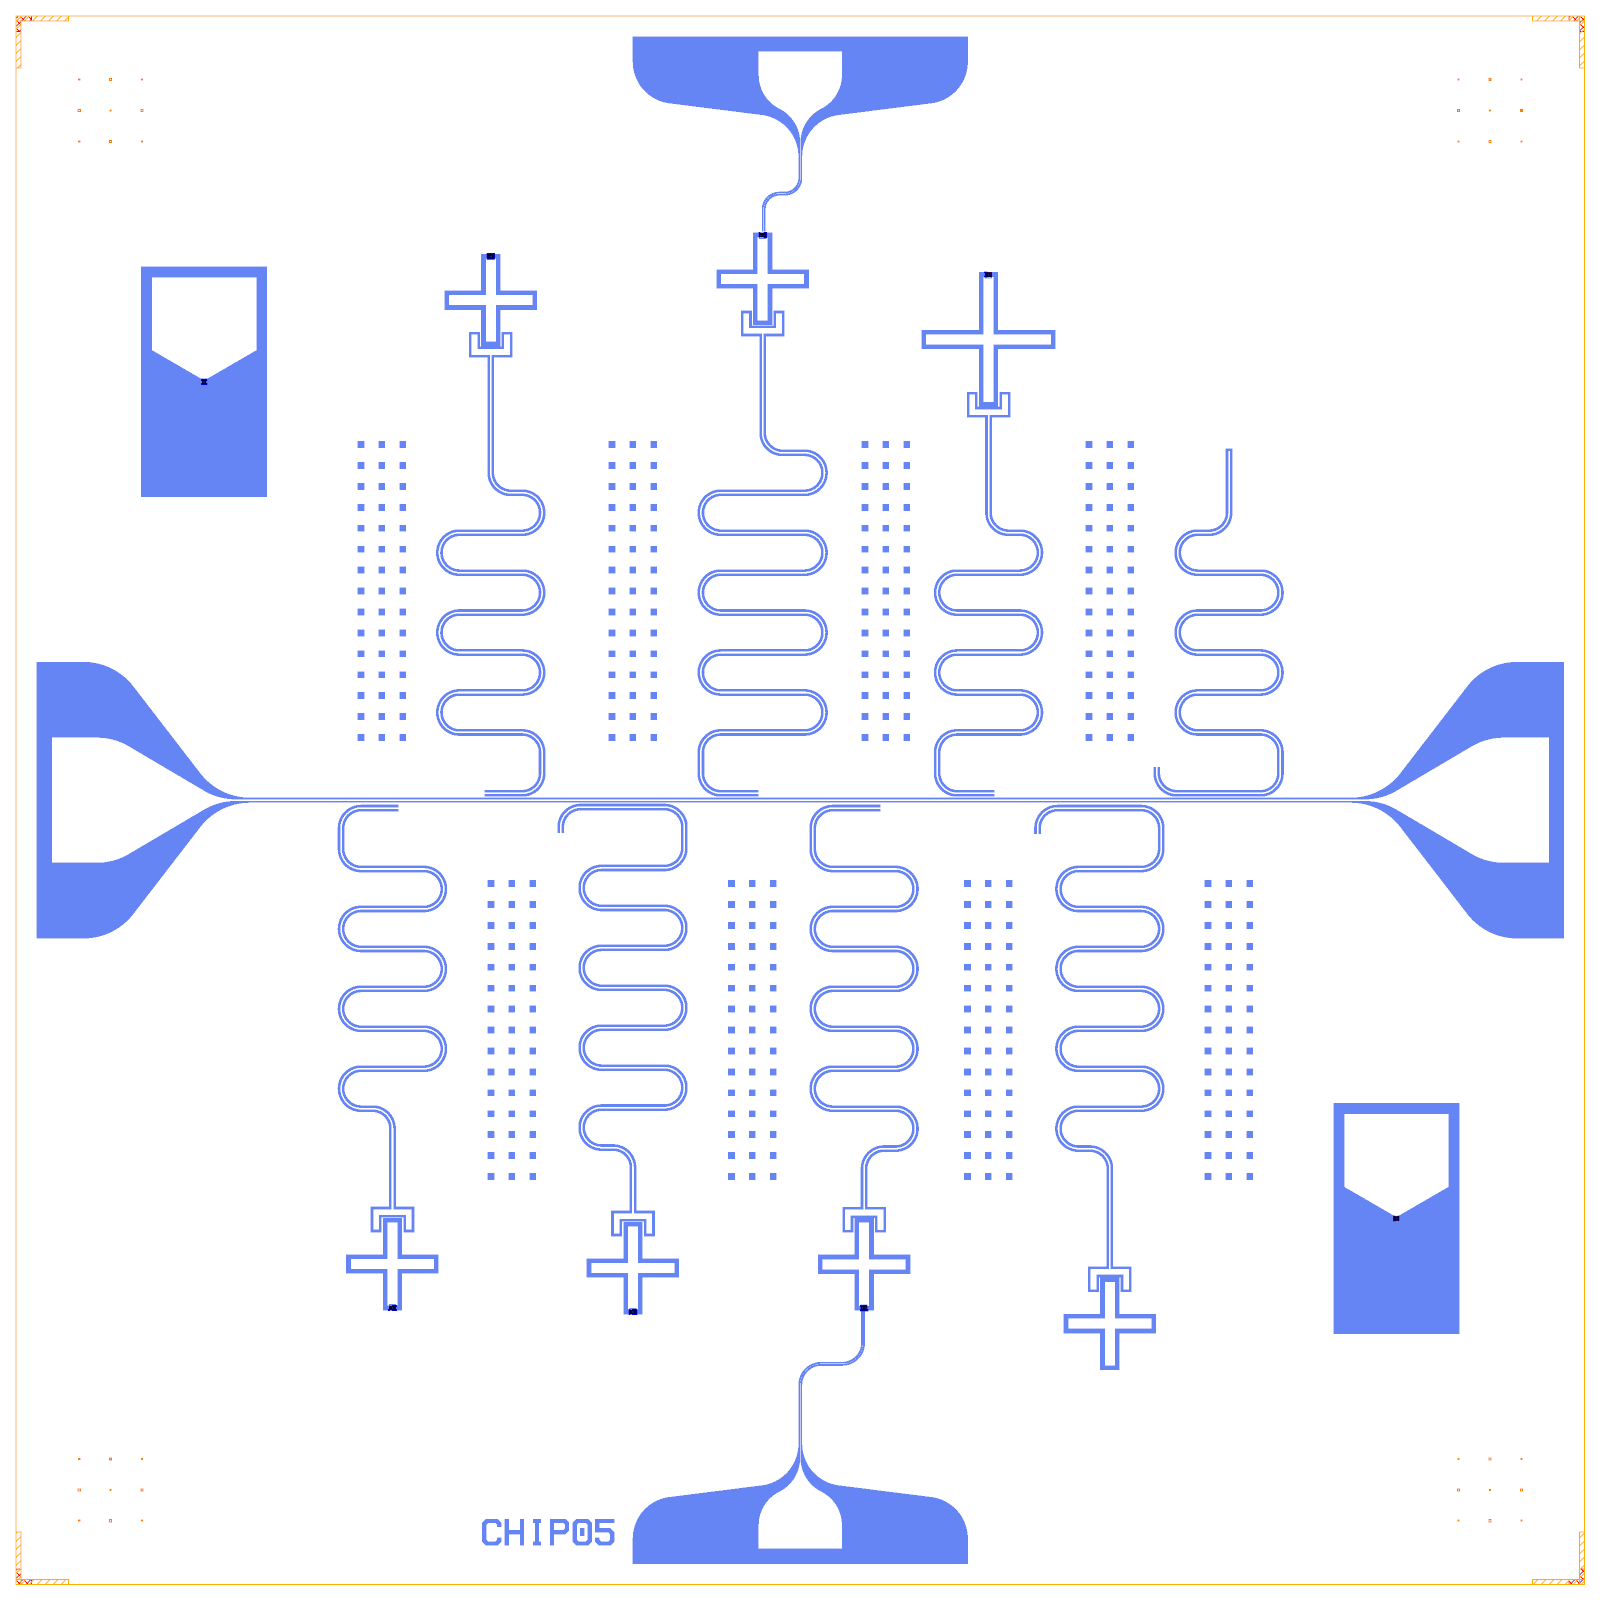

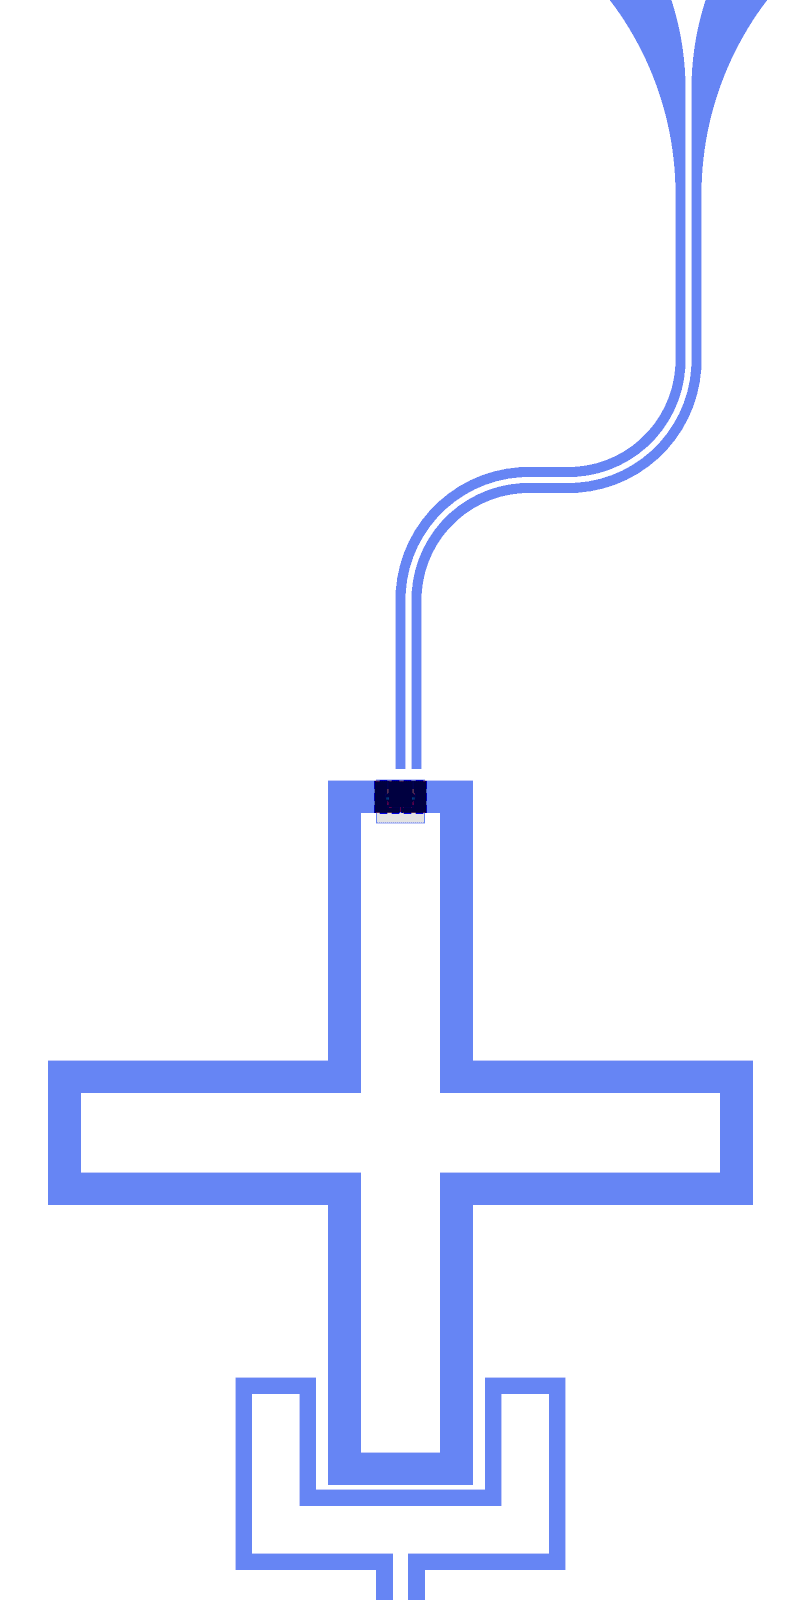

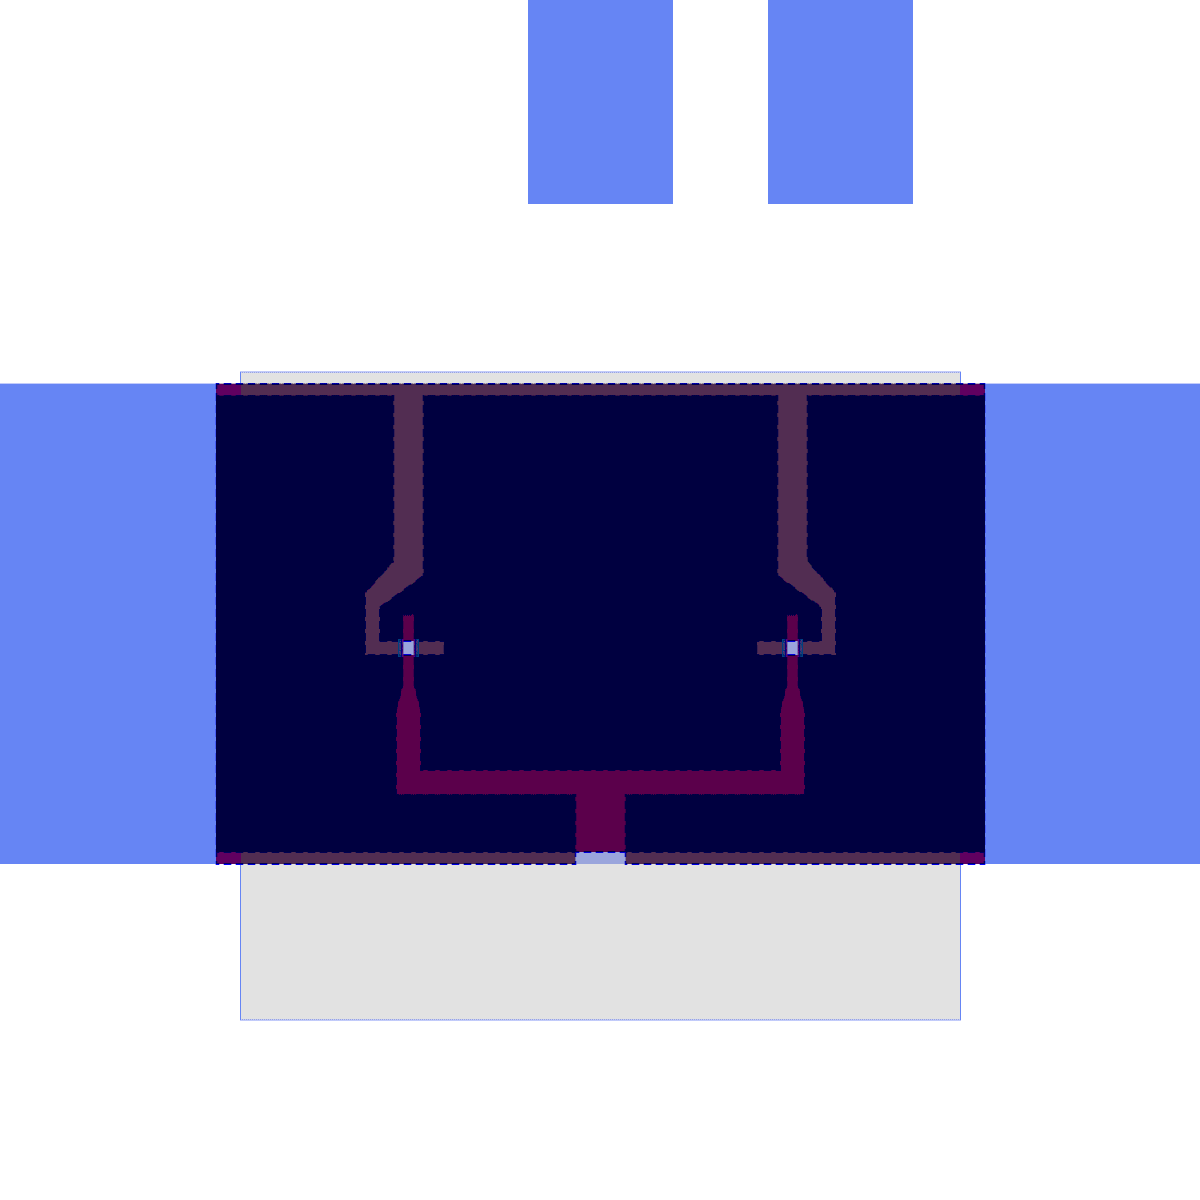

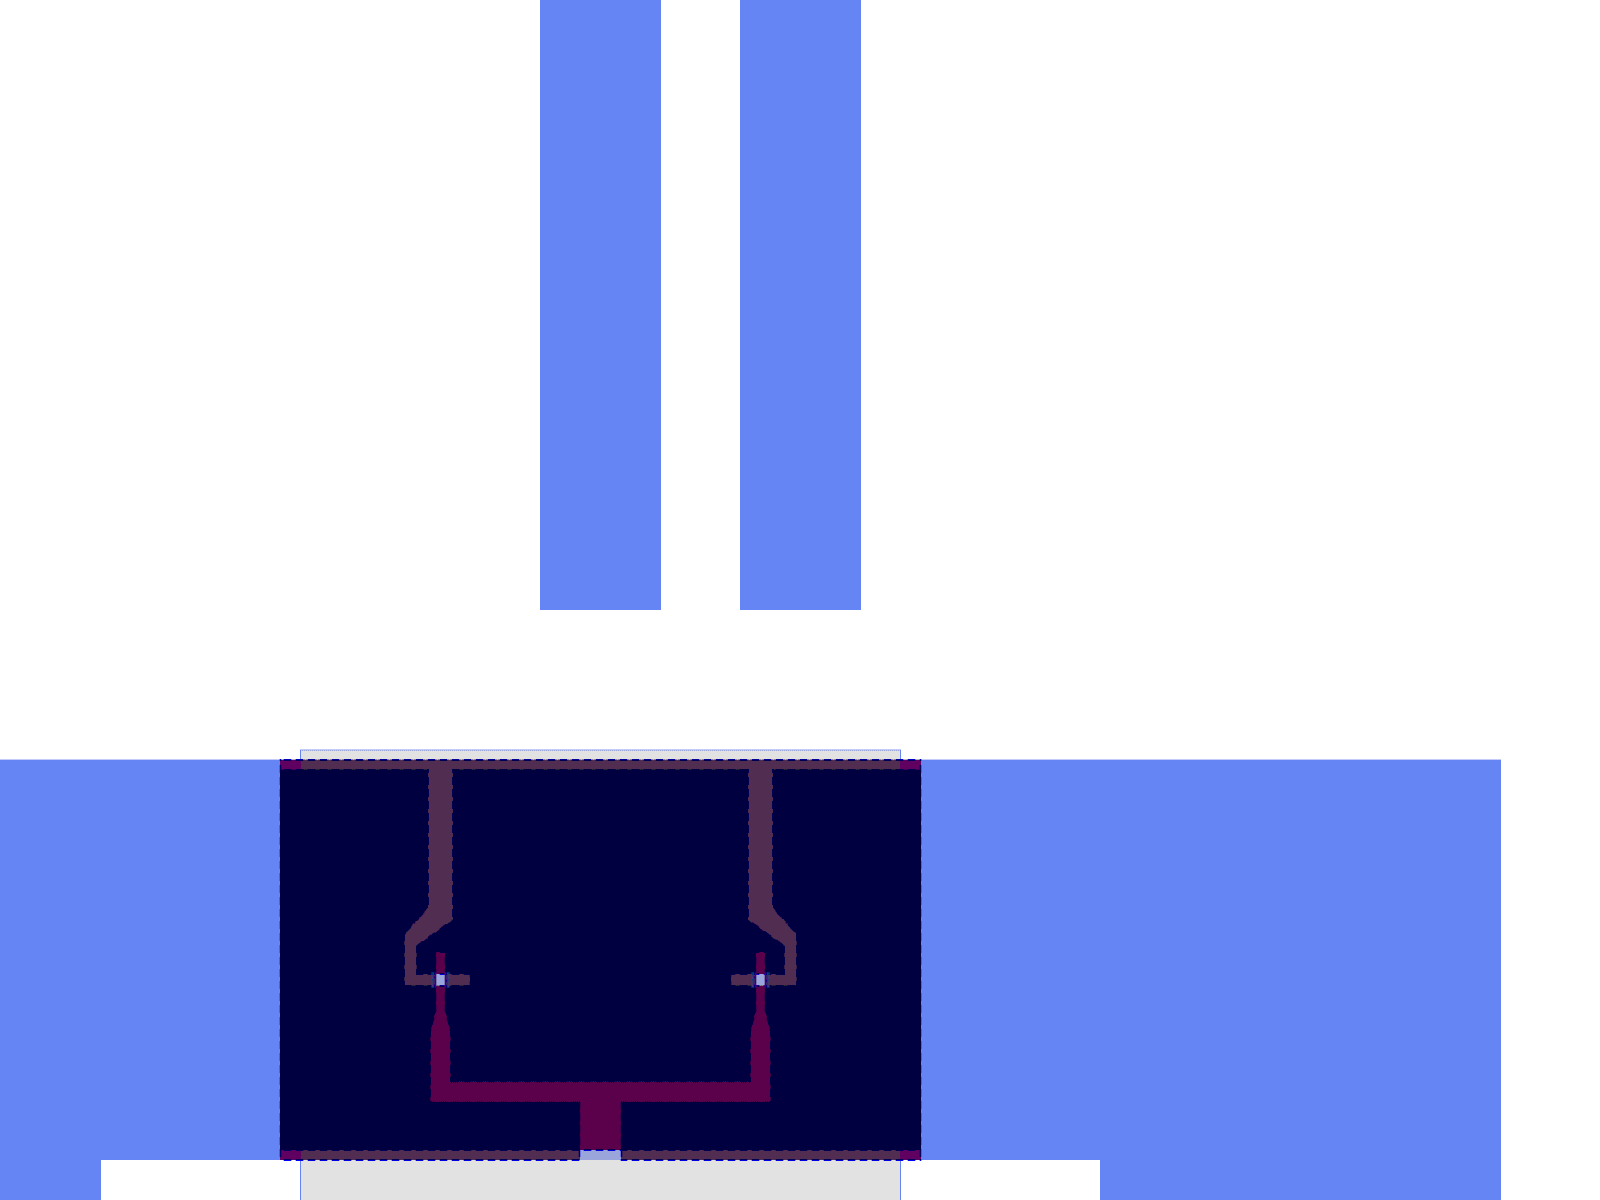

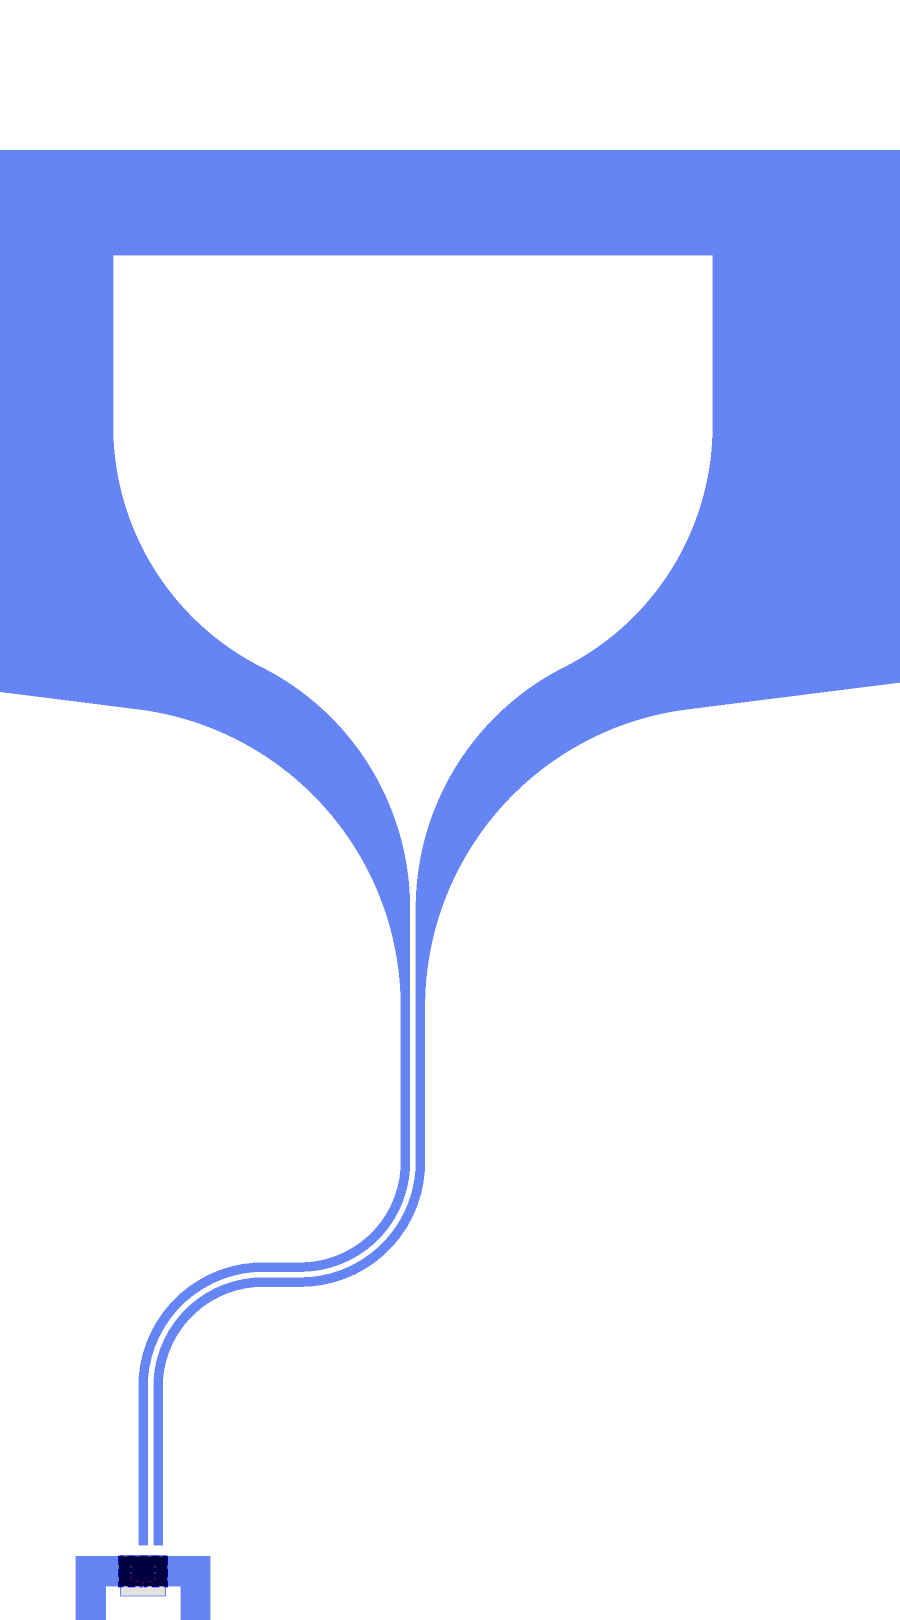

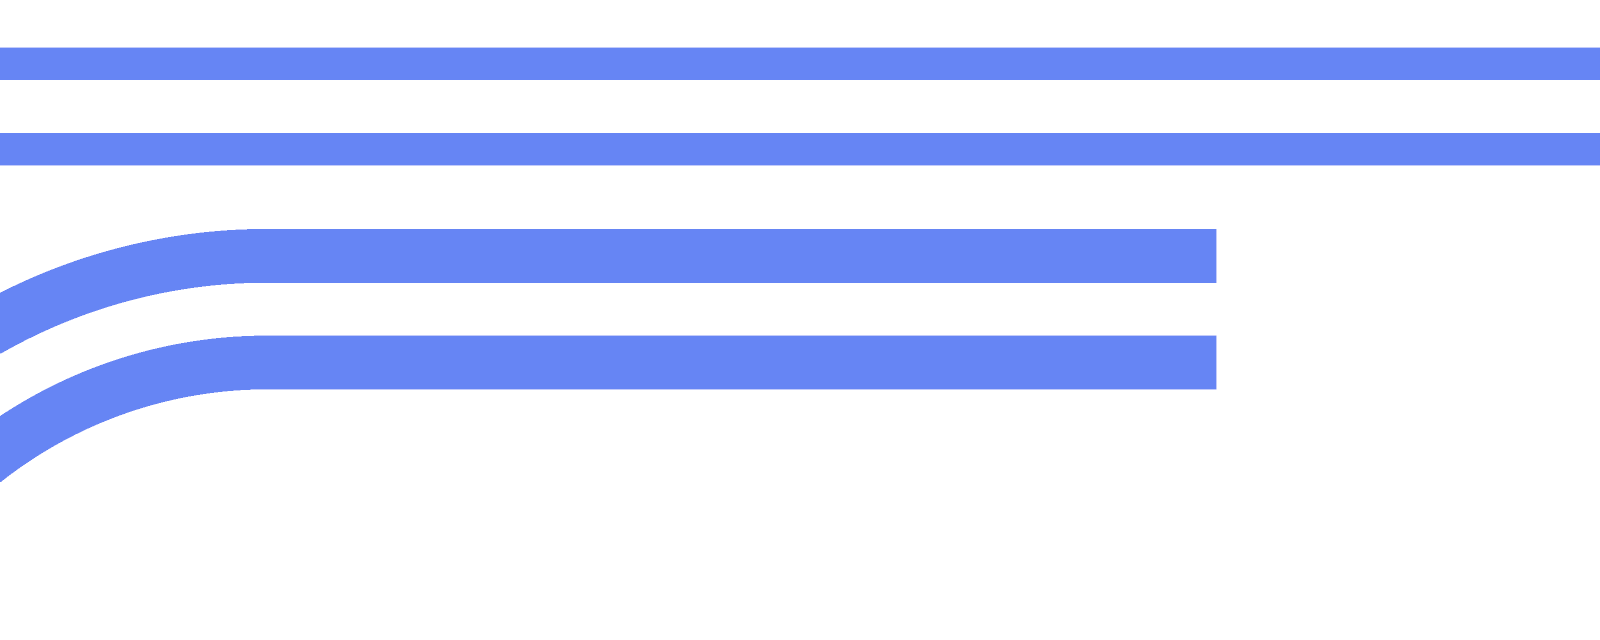

WindowsPath('examples/designs/legacy/chip_05_flux_tlqubits_coupler.png')

In [17]:
X4, Y4 = L.origin(d, "Q4")              # Q4 centre (Designer frame)
XF, YF = C.port_xy(d, "Q4.flux")
XC = C.port_xy(d, "FL.a")[1]            # feedline y after centring
C.show_snapshot(d, OUT / f"{ID}.png")
C.show_snapshot(d, OUT / f"{ID}_q4.png", box=(X4 - 250, Y4 - 292, X4 + 250, Y4 + 708), size=(800, 1600), width=320)
C.show_snapshot(d, OUT / f"{ID}_squid.png", box=(X4 - 25, Y4 + 186, X4 + 25, Y4 + 236), size=(1200, 1200), width=360)
C.show_snapshot(d, OUT / f"{ID}_fluxtip.png", box=(X4 - 30, Y4 + 198, X4 + 50, Y4 + 258), size=(1600, 1200), width=400)
C.show_snapshot(d, OUT / f"{ID}_fluxpad.png", box=(XF - 100, YF - 50, XF + 500, L.H), size=(900, 1620), width=300)
C.show_snapshot(d, OUT / f"{ID}_coupler.png", box=(1600, XC - 100, 1900, XC + 20), size=(1600, 640))

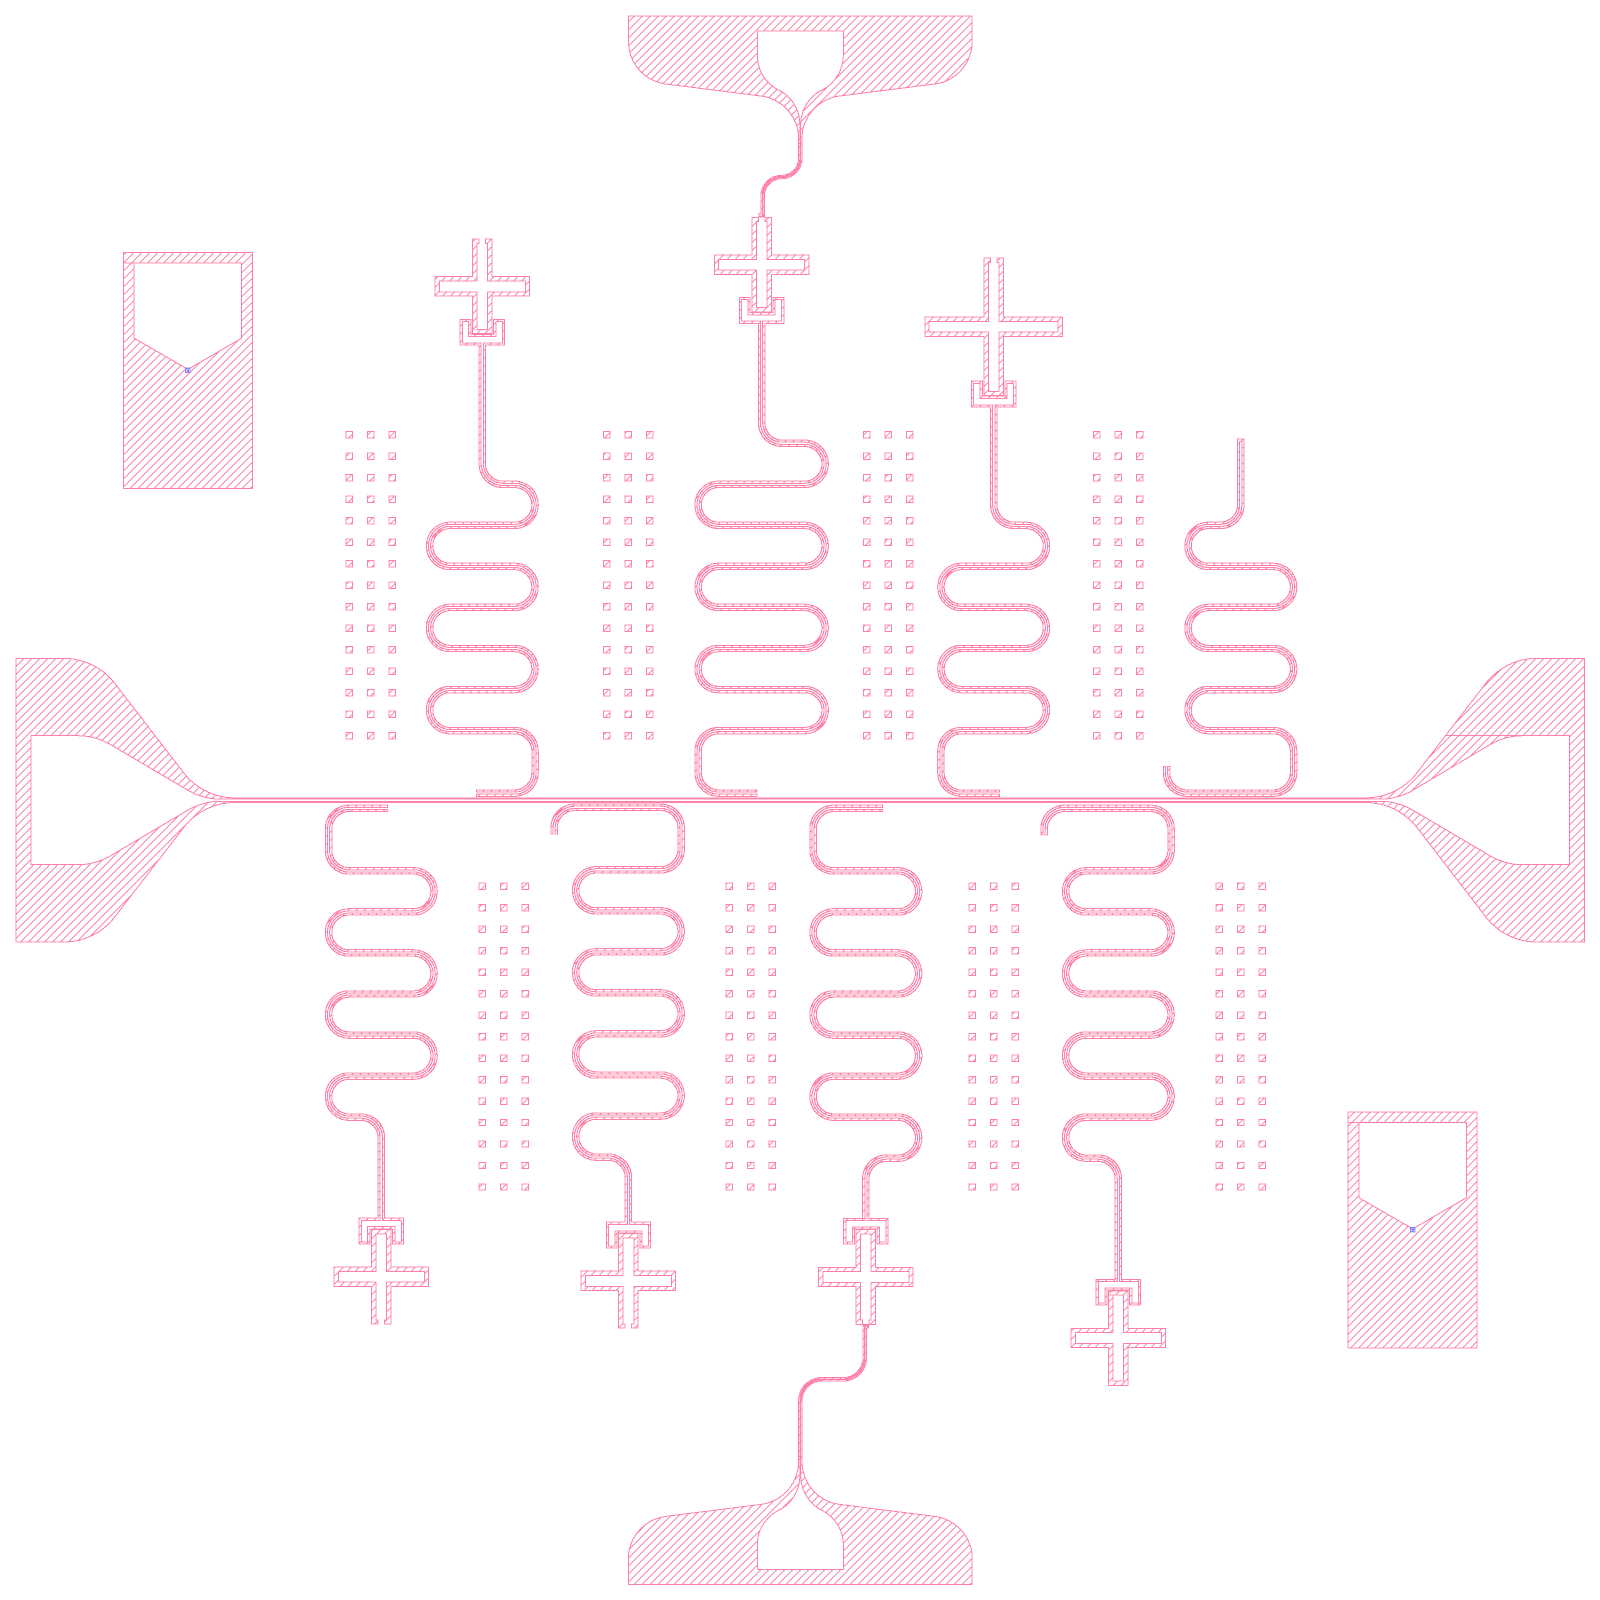

| instance | legacy etch (µm²) | rebuilt etch (µm²) | XOR (µm²) | XOR / legacy |
|---|---|---|---|---|
| FL | 61920 | 61920 | 0.0 | 0.00% |
| P1 | 493800 | 493800 | 0.0 | 0.00% |
| P2 | 493800 | 493800 | 0.0 | 0.00% |
| R1 | 94359 | 94359 | 0.0 | 0.00% |
| R2 | 97959 | 97959 | 0.0 | 0.00% |
| R3 | 111359 | 111359 | 0.0 | 0.00% |
| R4 | 123559 | 123559 | 0.0 | 0.00% |
| R5 | 103559 | 103559 | 0.0 | 0.00% |
| R6 | 84559 | 84559 | 0.0 | 0.00% |
| R7 | 116359 | 116359 | 0.0 | 0.00% |
| R8 | 89859 | 89859 | 0.0 | 0.00% |
| Q1 | 41220 | 41220 | 0.0 | 0.00% |
| Q2 | 41220 | 41220 | 0.0 | 0.00% |
| Q3 | 41220 | 41220 | 0.0 | 0.00% |
| Q4 | 41220 | 41220 | 0.0 | 0.00% |
| Q5 | 41220 | 41220 | 0.0 | 0.00% |
| Q6 | 57220 | 57220 | 0.0 | 0.00% |
| Q7 | 41820 | 41820 | 0.0 | 0.00% |
| TP1 | 448393 | 448393 | 0.0 | 0.00% |
| TP2 | 448393 | 448393 | 0.0 | 0.00% |
| H0 | 40500 | 40500 | 0.0 | 0.00% |
| H1 | 40500 | 40500 | 0.0 | 0.00% |
| H2 | 40500 | 40500 | 0.0 | 0.00% |
| H3 | 40500 | 40500 | 0.0 | 0.00% |
| H4 | 40500 | 40500 | 0.0 | 0.00% |
| H5 | 40500 | 40500 | 0.0 | 0.00% |
| H6 | 40500 | 40500 | 0.0 | 0.00% |
| H7 | 40500 | 40500 | 0.0 | 0.00% |
| FLUX4 | 5596 | 5351 | 3654.7 | 65.31% |
| FLUX5 | 10222 | 9869 | 403.8 | 3.95% |
| PFT | 445000 | 445000 | 0.0 | 0.00% |
| PFB | 445000 | 445000 | 0.0 | 0.00% |

max XOR without the flux lines: 0.0 µm²


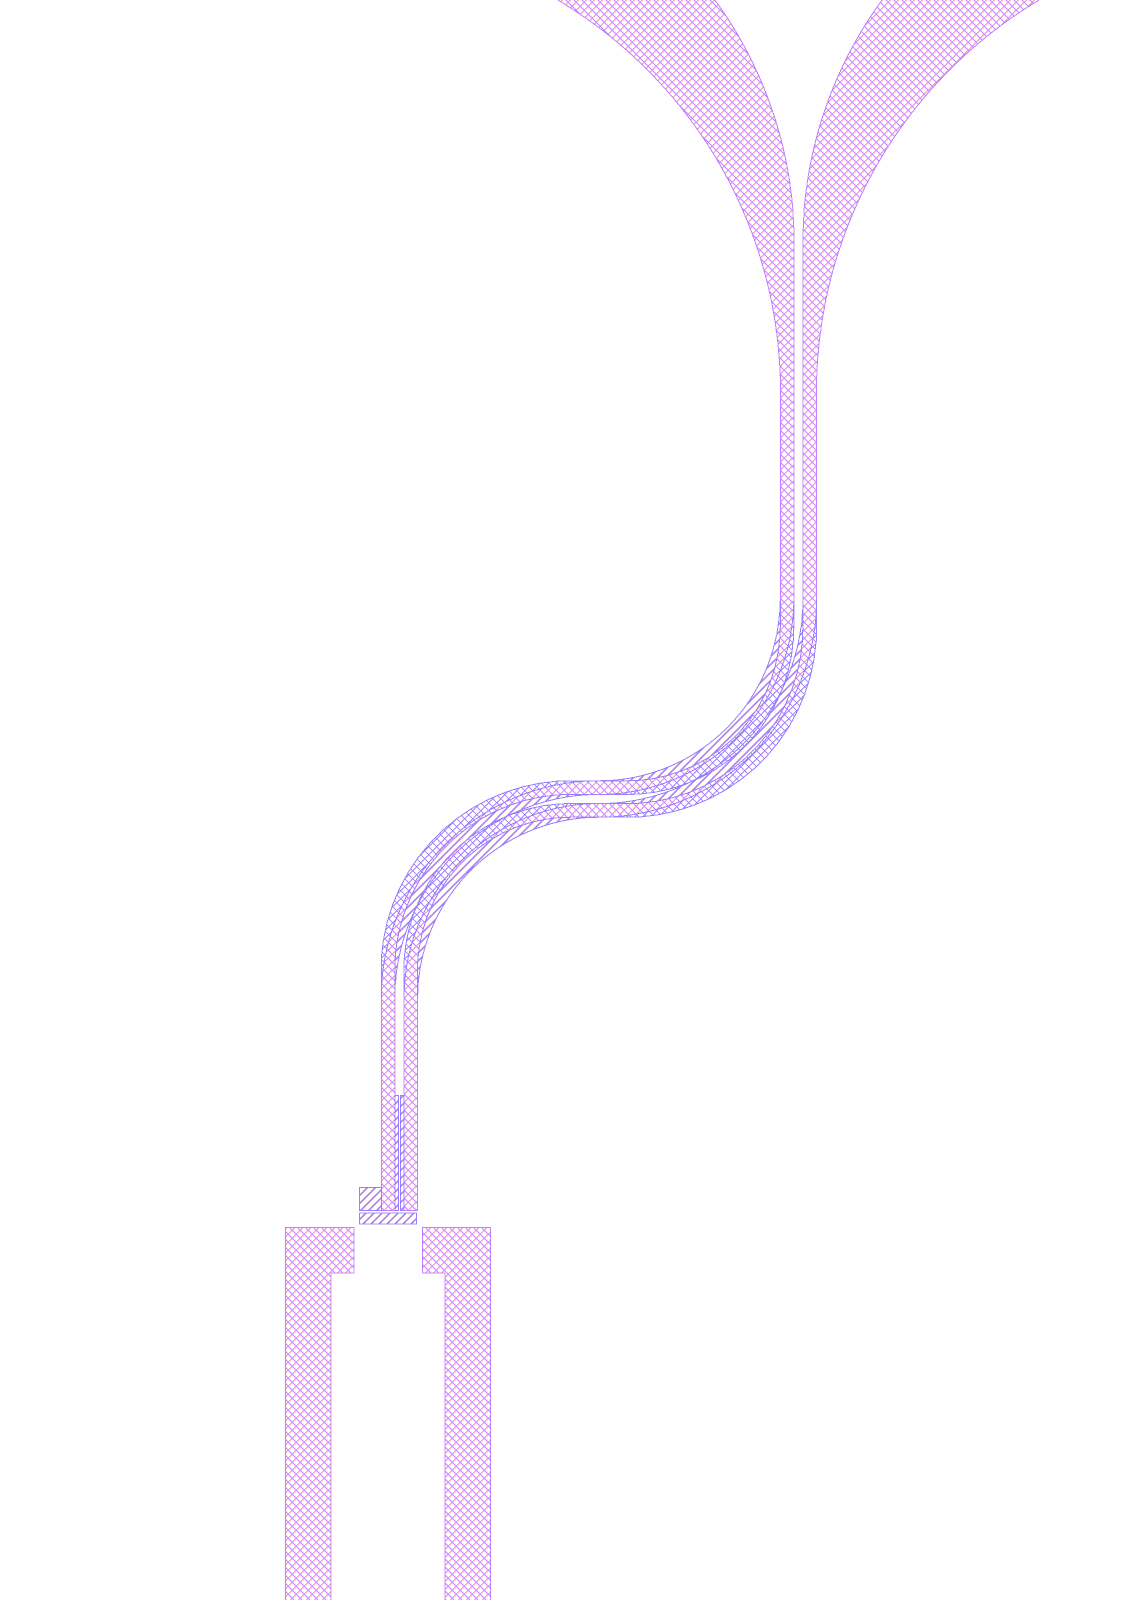

| instance | layer | legacy (µm²) | rebuilt (µm²) | XOR (µm²) |
|---|---|---|---|---|
| J1 | straight finger 2/0 | 630.987 | 630.987 | 0.0000 |
| J2 | straight finger 2/0 | 630.987 | 630.987 | 0.0000 |
| J3 | straight finger 2/0 | 630.987 | 630.987 | 0.0000 |
| J4 | straight finger 2/0 | 606.276 | 606.276 | 0.0000 |
| J5 | straight finger 2/0 | 606.276 | 606.276 | 0.0000 |
| J6 | straight finger 2/0 | 625.579 | 625.579 | 0.0000 |
| J1 | bent finger 4/0 | 593.699 | 593.699 | 0.0000 |
| J2 | bent finger 4/0 | 593.699 | 593.699 | 0.0000 |
| J3 | bent finger 4/0 | 593.699 | 593.699 | 0.0000 |
| J4 | bent finger 4/0 | 579.398 | 579.398 | 0.0000 |
| J5 | bent finger 4/0 | 579.398 | 579.398 | 0.0000 |
| J6 | bent finger 4/0 | 593.699 | 593.699 | 0.0000 |
| J1 | HSQ spacer (legacy 500/0 → 50/0) | 0.280 | 0.280 | 0.0000 |
| J2 | HSQ spacer (legacy 500/0 → 50/0) | 0.280 | 0.280 | 0.0000 |
| J3 | HSQ spacer (legacy 500/0 → 50/0) | 0.280 | 0.280 | 0.0000 |
| J4 | HSQ spacer (legacy 500/0 → 50/0) | 0.561 | 0.561 | 0.0000 |
| J5 | HSQ spacer (legacy 500/0 → 50/0) | 0.561 | 0.561 | 0.0000 |
| J6 | HSQ spacer (legacy 500/0 → 50/0) | 0.280 | 0.280 | 0.0000 |

max junction-layer XOR: 0.0 µm²


In [18]:
import klayout.db as pya


def legacy_flux_lines(port_y, jog_y):
    """chip_05_flux_TLQubits.py, flux lines (legacy frame, dbu 0.001), transcribed; the pad port and the jog at
    the PDK pad position (``port_y`` / ``jog_y``: {4: y, 5: y}, legacy frame), everything else as drawn."""
    dbu, g = 0.001, 6
    pts = lambda p: [pya.Point(pya.DPoint(x / dbu, y / dbu)) for x, y in p]
    out = {}
    for key, q, x_jog, (y_tip, y_end), (bx, by), s in (
            ("FLUX4", 4, -175, (2770, 2719.5), (-180, 2716), 1),
            ("FLUX5", 5, 300, (-2490, -2446.5), (305, -2443), -1)):
        thick = [[0, port_y[q]], [0, jog_y[q]], [x_jog, jog_y[q]], [x_jog, y_tip]]
        thin = [[x_jog, y_tip], [x_jog, y_end]]
        line = (pya.Region(pya.Path(pts(thick), (2 * g + 4) / dbu).round_corners(100 / dbu, 300))
                - pya.Region(pya.Path(pts(thick), 4 / dbu).round_corners(100 / dbu, 300)))
        tip = pya.Region(pya.Path(pts(thin), (2 * g + 4) / dbu)) - pya.Region(pya.Path(pts(thin), 1 / dbu))
        gnd = pya.Region().insert(pya.Box(int(25 / dbu), int(5 / dbu)).transformed(pya.Trans(0, False, bx / dbu, by / dbu)))
        box = pya.Region().insert(pya.Box(int(25 / dbu), int(10 / dbu)).transformed(
            pya.Trans(0, False, bx / dbu, (by + s * 8.5) / dbu)))
        out[key] = line + tip + gnd + (box & tip) + (box - pya.Region((box & tip).bbox()))
    return out


if L.legacy_available():
    import _legacy_b as LB
    from quantcore_circuits.live.snapshot import snapshot
    legacy_y = lambda ref: C.port_xy(d, ref)[1] - L.H / 2 - SHIFT[1]                   # Designer → legacy frame
    PORT_Y = {4: legacy_y("PFT.a"), 5: legacy_y("PFB.a")}                              # flux pads at the PDK rule
    JOG_Y = {q: y - L.H / 2 for q, y in JOG.items()}                                 # set before the centring
    cut_y = lambda i, y: y + (100 if i == 6 else 0) + (207 if y > 0 else -207)       # CLEARER centre
    tps = [(f"TP{k}", L.legacy_script_cell("testPad_Nb_TL_HSQ.py", "create_testPad", "TEST_TL", bf / 0.2, 0.6,
                                           tmp=f"build/legacy_a/chip_05/tp{k}"), x, y, 0, False)
           for k, (x, y, bf) in enumerate(TESTPADS, 1)]
    ref = L.xmon_feedline_reference(
        ID, feed=FEED | {"length": 2 * x_pad}, pads=[(PAD, -x_pad, 0, 3), (PAD, x_pad, 0, 1)],   # PDK pad position
        resonators=[(f"R{n}", RES | over, x, y, 0, mirror) for n, x, y, mirror, over, f in RROWS],
        xmons=[(f"Q{i}", BIG if i == 6 else XMON, x, y, 0 if i % 2 else 2, False) for i, (x, y, js) in enumerate(QUBITS, 1)],
        testpads=tps, regions=list(legacy_flux_lines(PORT_Y, JOG_Y).items()),
        etches=[(f"H{k}", [(x - 50 + a * 100 - 15, y + b * 100 - 15, x - 50 + a * 100 + 15, y + b * 100 + 15)
                           for a in range(3) for b in range(15)]) for k, (x, y) in enumerate(HOLES)],
        cutters=[(x - 15, cut_y(i, y) - 13.5, x + 15, cut_y(i, y) + 13.5) for i, (x, y, js) in enumerate(QUBITS, 1) if js])
    ref.pcell("PFT", "Connector Pad", {"fab": True, **TINY}, 0, PORT_Y[4], 2, False)
    ref.pcell("PFB", "Connector Pad", {"fab": True, **TINY}, 0, PORT_Y[5], 2, True)
    ref = L.shift_reference(ref, *SHIFT)
    snapshot(ref.write(f"build/legacy_a/{ID}_legacy.oas"), OUT / f"{ID}_legacy.png")
    display(Image(filename=str(OUT / f"{ID}_legacy.png"), width=640))
    table, xor = L.xor_table(d, ref)
    display(Markdown(table))
    print("max XOR without the flux lines:", round(max(v for k, v in xor.items() if not k.startswith("FLUX")), 3), "µm²")
    L.xor_png(d, ref, OUT / f"{ID}_xor_flux4.png", box=(XF - 175, YF - 120, XF + 325, YF + 480), size=(1140, 1600))
    display(Image(filename=str(OUT / f"{ID}_xor_flux4.png"), width=360))
    # junction layers: the legacy junction / SQUID cells at (x, y ± 210) (+100 for Q6), Trans(0, flag) toggling per qubit
    jref, flag = LB.legacy_chip("chip_05_junctions"), True
    for i, (x, y, js) in enumerate(QUBITS[:-1], 1):
        flag = not flag
        script, func = ("squid_creator_HSQ.py", "create_squid") if i in SQUIDS else ("junction_creator_HSQ.py", "create_junction")
        cell = L.legacy_script_cell(script, func, f"JUNC_{js}", js, SECOND_FINGER, tmp=f"build/legacy_c/chip_05/j{i}_js{js}")
        jref.cell_from(f"J{i}", *cell, x, y + (210 if y > 0 else -210) + (100 if i == 6 else 0), 0, flag)
    jref = L.shift_reference(jref, *SHIFT)
    jtable, jxor = LB.junction_xor(d, jref, names=[f"J{i}" for i in range(1, 7)])
    display(Markdown(jtable))
    print("max junction-layer XOR:", round(max(jxor.values()), 4), "µm²")
else:
    print("components/ (legacy library) not present: no legacy reference")

## 16 · Summary

- **Matches the source:** the eight resonators, the seven Xmon crosses and claws with their junction windows, the
  flux holes, the test pads, and the four pads + feedline at their PDK position (XOR 0 µm² on every one); the six
  junctions on 2/0, 4/0 and the HSQ layer (XOR 0 against the legacy `junction_creator_HSQ` / `squid_creator_HSQ`
  cells, indexing fixed, #11).
- **Differs, by the PDK:** the four pads `pad_edge` = 100 µm from the die edge (feedline 5160 µm; flux-pad ports at
  ±3055 µm instead of ±3155); the flux lines' jogs moved with their pads (FLUX4 at y +2900, FLUX5 at −2695, legacy
  frame: the same 155 / 360 µm leads, so the 75 / 100 µm corners fit; 446 / 823 µm long); the PDK frame and device
  ID `CHIP05` (bottom edge, left of the flux pad). Centring shift (0, 0): the chip is symmetric.
- **Differs, legacy approximations:** FLUX4's 75 µm corners (#11) and the legacy 1 µm tips and ground boxes not
  drawn (XOR FLUX4 3655 µm², FLUX5 404 µm²).
- **Cheese:** the original's flux holes, no PDK band (fab cheese source "original"; before this pass the build
  added the band).
- **Open:** 3 `pdk_rn` design warnings (Q4 / Q5 22.5 kΩ, Q6 28.1 kΩ); Q1/R1 and Q2/R2 collide; Q4 tunes from 7.80
  to 6.53 GHz at Φ = 0.25 Φ0 (step 13).